# **GIAI ĐOẠN 1: IMPORT, TIỀN XỬ LÝ VÀ TRỰC QUAN HÓA DỮ LIỆU (EDA)**

In [1]:
!pip install pyclustering

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 34.9 MB/s eta 0:00:0000:0100:01
  Preparing metadata (setup.py) ... done
  Created wheel for pyclustering: filename=pyclustering-0.10.1.2-py3-none-any.whl size=2395194 sha256=b95145bdc1d9286bd3292c7c4063dad367c3177119d0b4733535e9ec01e1ecce
  Stored in directory: /root/.cache/pip/wheels/68/29/b4/131bd7deec3663cc311ab9aa64d6517c3e3ec24bcadfc32f74
Successfully built pyclustering


In [47]:
import joblib
import json
import zipfile
import absl.logging
import cv2
import gdown
import pandas as pd
import numpy as np
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import confusion_matrix
from google.colab import drive
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from sklearn.utils import class_weight
from sklearn.metrics import classification_report
from sklearn.ensemble import IsolationForest
from pyclustering.cluster.cure import cure
from pyclustering.utils import draw_clusters
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

**Kết nối Drive lấy tập Dataset xử lý**

In [3]:
print("Đang kéo file chuẩn từ Google Drive về Kaggle...")
file_id = '1KwTKezCswgEkgyUuvsjHGgkCQPYDqG4K' 
url = f'https://drive.google.com/uc?id={file_id}'

# Tải file về đặt tên là LSWMD.pkl
gdown.download(url, 'LSWMD.pkl', quiet=False)
print("Đang load dữ liệu vào RAM...")

file_path = 'LSWMD.pkl'
df = pd.read_pickle(file_path)

# Kiểm tra lại số lượng dòng Null để xác nhận file chuẩn
print(f"Tổng số dòng của bảng: {len(df):,}")
print(f"Số dòng Null trong cột failureType: {df['failureType'].isnull().sum():,}")
print("Đã sẵn sàng chạy tiếp các bước tiếp theo!")

Đang kéo file chuẩn từ Google Drive về Kaggle...


Downloading...
From (original): https://drive.google.com/uc?id=1KwTKezCswgEkgyUuvsjHGgkCQPYDqG4K
From (redirected): https://drive.google.com/uc?id=1KwTKezCswgEkgyUuvsjHGgkCQPYDqG4K&confirm=t&uuid=e31d742b-09d5-42f8-a6bd-5b5bf1ce766a
To: /kaggle/working/LSWMD.pkl
100%|██████████| 2.10G/2.10G [00:22<00:00, 92.0MB/s]


Đang load dữ liệu vào RAM...
Tổng số dòng của bảng: 811,457
Số dòng Null trong cột failureType: 0
Đã sẵn sàng chạy tiếp các bước tiếp theo!


**Hiển thị dữ liệu**

In [4]:
print("Đang load dữ liệu từ file pickle, quá trình này có thể mất vài phút do file lớn...")
df = pd.read_pickle(file_path)
print("Đã load dữ liệu thành công!\n")

print("="*60)
print("1. KÍCH THƯỚC & DUNG LƯỢNG TẬP DỮ LIỆU")
print("="*60)
print(f"- Tổng số dòng (Mẫu Wafer): {df.shape[0]:,}")
print(f"- Tổng số cột (Đặc trưng): {df.shape[1]}")
# memory_usage='deep' giúp tính toán chính xác số MB RAM mà list/array đang chiếm
df.info(memory_usage='deep')

print("\n" + "="*60)
print("2. THỐNG KÊ DỮ LIỆU THIẾU (MISSING VALUES)")
print("="*60)
# Kiểm tra xem cột nào đang bị trống (NaN) và chiếm tỉ lệ bao nhiêu %
missing_data = df.isnull().sum()
missing_percent = (missing_data / len(df)) * 100
missing_df = pd.DataFrame({'Số lượng Null': missing_data, 'Tỷ lệ Null (%)': missing_percent})
display(missing_df.round(2))

print("\n" + "="*60)
print("3. XEM TRƯỚC DỮ LIỆU (10 DÒNG ĐẦU & 5 DÒNG NGẪU NHIÊN)")
print("="*60)
print("--- 10 dòng đầu tiên (Đầu bảng) ---")
display(df.head(10))

print("\n--- 5 dòng ngẫu nhiên (Lấy random để check độ lộn xộn) ---")
# random_state=42 để mỗi lần chạy đều ra 5 dòng ngẫu nhiên giống nhau
display(df.sample(5, random_state=42))

Đang load dữ liệu từ file pickle, quá trình này có thể mất vài phút do file lớn...
Đã load dữ liệu thành công!

1. KÍCH THƯỚC & DUNG LƯỢNG TẬP DỮ LIỆU
- Tổng số dòng (Mẫu Wafer): 811,457
- Tổng số cột (Đặc trưng): 6
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 811457 entries, 0 to 811456
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   waferMap        811457 non-null  object 
 1   dieSize         811457 non-null  float64
 2   lotName         811457 non-null  object 
 3   waferIndex      811457 non-null  float64
 4   trianTestLabel  811457 non-null  object 
 5   failureType     811457 non-null  object 
dtypes: float64(2), object(4)
memory usage: 628.9 MB

2. THỐNG KÊ DỮ LIỆU THIẾU (MISSING VALUES)


,Số lượng Null,Tỷ lệ Null (%)
waferMap,0,0.0
dieSize,0,0.0
lotName,0,0.0
waferIndex,0,0.0
trianTestLabel,0,0.0
failureType,0,0.0



3. XEM TRƯỚC DỮ LIỆU (10 DÒNG ĐẦU & 5 DÒNG NGẪU NHIÊN)
--- 10 dòng đầu tiên (Đầu bảng) ---


,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,[[Training]],[[none]]
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,[[Training]],[[none]]
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,[[Training]],[[none]]
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4.0,[[Training]],[[none]]
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5.0,[[Training]],[[none]]
5,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,6.0,[[Training]],[[none]]
6,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,7.0,[[Training]],[[none]]
7,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,8.0,[[Training]],[[none]]
8,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,9.0,[[Training]],[[none]]
9,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,10.0,[[Training]],[[none]]



--- 5 dòng ngẫu nhiên (Lấy random để check độ lộn xộn) ---


,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType
552336,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,...",712.0,lot34696,6.0,[],[]
24803,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",776.0,lot2724,2.0,[],[]
426607,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",6052.0,lot25655,12.0,[],[]
722885,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 2, 1,...",518.0,lot43945,20.0,[[Test]],[[none]]
192536,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",6328.0,lot12178,18.0,[],[]


In [5]:
# 1. Rút phần text ra khỏi mảng 2 chiều một cách an toàn (tránh lỗi float)
df['failureType'] = df['failureType'].apply(
    lambda x: x[0][0] if isinstance(x, (np.ndarray, list)) and len(x) > 0 else np.nan
)
df['trianTestLabel'] = df['trianTestLabel'].apply(
    lambda x: x[0][0] if isinstance(x, (np.ndarray, list)) and len(x) > 0 else np.nan
)

# 2. Xóa các dòng NaN (loại bỏ khoảng 630k ảnh không nhãn lúc này)
df_labeled = df.dropna(subset=['failureType']).copy()

# 3. Đổi tên nhãn 'none' thành 'Normal' cho đúng bản chất
df_labeled['failureType'] = df_labeled['failureType'].replace('none', 'Normal')

# Tạo một DataFrame thống kê đếm số lượng và tính %
stats_df = df_labeled['failureType'].value_counts().to_frame(name='Số lượng')
stats_df['Tỷ lệ (%)'] = (stats_df['Số lượng'] / len(df_labeled) * 100).round(2)

print("--- THỐNG KÊ PHÂN BỔ 9 NHÃN (Bao gồm Normal + 8 loại lỗi) ---")
display(stats_df)

--- THỐNG KÊ PHÂN BỔ 9 NHÃN (Bao gồm Normal + 8 loại lỗi) ---


,Số lượng,Tỷ lệ (%)
failureType,,
Normal,147431,85.24
Edge-Ring,9680,5.60
Edge-Loc,5189,3.00
Center,4294,2.48
Loc,3593,2.08
Scratch,1193,0.69
Random,866,0.50
Donut,555,0.32
Near-full,149,0.09


**Làm sạch nhãn và Tách 2 bộ Subset (50k Có nhãn & 100k Không nhãn)**

In [6]:
# 1. Tách và lấy mẫu Normal bằng với số lượng lỗi
df_normal = df_labeled[df_labeled['failureType'] == 'Normal']
df_defect = df_labeled[df_labeled['failureType'] != 'Normal']

df_normal_sampled = df_normal.sample(n=len(df_defect), random_state=42)
df_subset = pd.concat([df_normal_sampled, df_defect]).reset_index(drop=True)

# 2. Lấy kích thước ma trận siêu tốc bằng lambda và thuộc tính .shape
df_subset['waferMapDim'] = df_subset['waferMap'].apply(lambda x: x.shape)

# === IN KẾT QUẢ TỔNG HỢP ===
print(f" Đã tạo Subset thành công! Tổng số lượng ảnh: {len(df_subset):,}")

print("\n--- PHÂN BỐ 9 NHÃN SAU KHI CÂN BẰNG ---")
display(df_subset['failureType'].value_counts().to_frame(name='Số lượng'))

print("\n--- 5 KÍCH THƯỚC MA TRẬN PHỔ BIẾN NHẤT ---")
display(df_subset['waferMapDim'].value_counts().head().to_frame(name='Số lượng Wafer'))

 Đã tạo Subset thành công! Tổng số lượng ảnh: 51,038

--- PHÂN BỐ 9 NHÃN SAU KHI CÂN BẰNG ---


,Số lượng
failureType,
Normal,25519
Edge-Ring,9680
Edge-Loc,5189
Center,4294
Loc,3593
Scratch,1193
Random,866
Donut,555
Near-full,149



--- 5 KÍCH THƯỚC MA TRẬN PHỔ BIẾN NHẤT ---


,Số lượng Wafer
waferMapDim,
"(25, 27)",5639
"(26, 26)",3133
"(30, 34)",2660
"(39, 37)",2641
"(29, 26)",2515


**Bộ subset nhỏ:** (Tỉ lệ 1:1)


In [7]:
# Chọn 64x64 làm chuẩn
TARGET_SIZE = (64, 64)

def resize_wafer_map(wm):
    # Ép kiểu về float32 hoặc uint8 trước khi dùng cv2
    wm_float = wm.astype(np.uint8)
    # Dùng cv2.INTER_NEAREST để bảo toàn tuyệt đối các số nguyên 0, 1, 2
    return cv2.resize(wm_float, dsize=TARGET_SIZE, interpolation=cv2.INTER_NEAREST)

print("Đang đồng bộ kích thước toàn bộ dữ liệu, vui lòng đợi...")
# Tạo cột mới chứa ma trận đã resize
df_subset['waferMap_resized'] = df_subset['waferMap'].apply(resize_wafer_map)

# Kiểm tra thử kích thước của mẫu đầu tiên sau khi xử lý
print("\nKích thước ma trận mẫu 1 sau resize:", df_subset['waferMap_resized'].iloc[0].shape)
print("Các giá trị duy nhất trong ma trận (chỉ được phép có 0, 1, 2):", np.unique(df_subset['waferMap_resized'].iloc[0]))

# Lưu toàn bộ dataframe sạch sẽ này thành một file pickle mới nhẹ gọn hơn
export_path = 'WM811K_subset_clean.pkl'
df_subset.to_pickle(export_path)
print(f"\nĐã xuất file thành phẩm tại thư mục hiện tại của Kaggle: {export_path}")

Đang đồng bộ kích thước toàn bộ dữ liệu, vui lòng đợi...

Kích thước ma trận mẫu 1 sau resize: (64, 64)
Các giá trị duy nhất trong ma trận (chỉ được phép có 0, 1, 2): [0 1 2]

Đã xuất file thành phẩm tại thư mục hiện tại của Kaggle: WM811K_subset_clean.pkl


**Bộ subset lớn:**

In [8]:
# 1. LẤY TẬP LỚN: Lọc ra các dòng bị NaN (không có nhãn)
df_unlabeled = df[df['failureType'].isna()].copy()
print(f"Tổng số ảnh không nhãn trong file gốc: {len(df_unlabeled)}")

# 2. Rút ngẫu nhiên 100.000 ảnh để tạo Tập Lớn (tránh tràn RAM Colab)
df_unlabeled_subset = df_unlabeled.sample(n=100000, random_state=42).copy()
print(f"Đã rút {len(df_unlabeled_subset)} ảnh không nhãn để xử lý.")

# 3. Resize toàn bộ về 64x64 giống hệt tập nhỏ để đồng bộ kích thước
TARGET_SIZE = (64, 64)
def resize_wafer_map(wm):
    wm_float = wm.astype(np.uint8)
    return cv2.resize(wm_float, dsize=TARGET_SIZE, interpolation=cv2.INTER_NEAREST)

print("Đang đồng bộ kích thước 100.000 ảnh không nhãn, thao tác này sẽ mất vài phút...")
df_unlabeled_subset['waferMap_resized'] = df_unlabeled_subset['waferMap'].apply(resize_wafer_map)

# 4. Thêm 'waferMap' vào danh sách để không bị lỗi KeyError sau này
columns_to_keep = ['waferMap', 'waferMap_resized', 'dieSize', 'lotName', 'waferIndex']
df_final_large = df_unlabeled_subset[columns_to_keep]

export_path_large = 'WM811K_unlabeled_100k.pkl'

df_final_large.to_pickle(export_path_large)
print(f"\nĐã xuất file thành phẩm 100k tại thư mục hiện tại của Kaggle: {export_path_large}")

Tổng số ảnh không nhãn trong file gốc: 638507
Đã rút 100000 ảnh không nhãn để xử lý.
Đang đồng bộ kích thước 100.000 ảnh không nhãn, thao tác này sẽ mất vài phút...

Đã xuất file thành phẩm 100k tại thư mục hiện tại của Kaggle: WM811K_unlabeled_100k.pkl


**Báo cáo chi tiết chuyên sâu cho 2 bộ**

In [21]:
# --- TỰ ĐỘNG BỔ SUNG CỘT waferMapDim NẾU CHƯA CÓ TRONG RAM ---
if 'waferMapDim' not in df_subset.columns:
    df_subset['waferMapDim'] = df_subset['waferMap'].apply(lambda x: x.shape)

if 'waferMapDim' not in df_final_large.columns:
    df_final_large['waferMapDim'] = df_final_large['waferMap'].apply(lambda x: x.shape)

# Tính dung lượng RAM (MB) của từng bộ
mem_50k = df_subset.memory_usage(deep=True).sum() / (1024 ** 2)
mem_100k = df_final_large.memory_usage(deep=True).sum() / (1024 ** 2)

print("=" * 80)
print("1. BẢNG SO SÁNH TỔNG QUAN 2 BỘ DỮ LIỆU THỰC CHIẾN (50K vs 100K)")
print("=" * 80)
summary_comparison = pd.DataFrame({
    'Tiêu chí': [
        'Tên biến trong Code',
        'Số lượng mẫu (Wafer)',
        'Các cột thuộc tính hiện có',
        'Trạng thái nhãn (failureType)',
        'Kích thước ma trận sau chuẩn hóa',
        'Giá trị điểm ảnh (Pixel Values)',
        'Số Lô sản xuất (lotName) độc lập',
        'Dung lượng chiếm dụng RAM (MB)',
        'Vai trò trong Pipeline'
    ],
    'Bộ 1: Tập Có Nhãn (~50K)': [
        'df_subset',
        f"{len(df_subset):,} mẫu",
        f"{df_subset.shape[1]} cột: {', '.join(df_subset.columns)}",
        "Đã gán nhãn (9 classes: Normal + 8 lỗi)",
        "64 x 64 (uint8)",
        f"{np.unique(df_subset['waferMap_resized'].iloc[0]).tolist()}",
        f"{df_subset['lotName'].nunique():,} lô",
        f"{mem_50k:.2f} MB",
        "Train/Test CNN v1 & Đối chiếu chéo K-Means"
    ],
    'Bộ 2: Tập Không Nhãn (100K)': [
        'df_final_large',
        f"{len(df_final_large):,} mẫu",
        f"{df_final_large.shape[1]} cột: {', '.join(df_final_large.columns)}",
        "Chưa có nhãn (100% Unlabeled)",
        "64 x 64 (uint8)",
        f"{np.unique(df_final_large['waferMap_resized'].iloc[0]).tolist()}",
        f"{df_final_large['lotName'].nunique():,} lô",
        f"{mem_100k:.2f} MB",
        "Nén PCA, Gom cụm K-Means, Pseudo-Labeling, Isolation Forest & CURE"
    ]
})
display(summary_comparison.style.hide(axis='index'))

# ==============================================================================
print("\n" + "=" * 80)
print("2. CHI TIẾT BỘ 50K CÓ NHÃN (df_subset) - CƠ CẤU 9 NHÃN SAU KHI CÂN BẰNG 1:1")
print("=" * 80)
stats_50k = df_subset['failureType'].value_counts().to_frame(name='Số lượng mẫu')
stats_50k['Tỷ lệ trong tập 50k (%)'] = (stats_50k['Số lượng mẫu'] / len(df_subset) * 100).round(2)
stats_50k['Nhóm phân loại'] = stats_50k.index.map(lambda x: 'Bình thường (50%)' if x == 'Normal' else 'Khuyết tật (50%)')
display(stats_50k)

print("--- 5 dòng mẫu ngẫu nhiên của Bộ 50K Có Nhãn (df_subset) ---")
display(df_subset[['lotName', 'waferIndex', 'dieSize', 'waferMapDim', 'failureType']].sample(5, random_state=42))

# ==============================================================================
print("\n" + "=" * 80)
print("3. CHI TIẾT BỘ 100K KHÔNG NHÃN (df_final_large) - ĐẶC TRƯNG VẬT LÝ & KÍCH THƯỚC")
print("=" * 80)

top_dims_50k = df_subset['waferMapDim'].value_counts().head(5).reset_index()
top_dims_50k.columns = ['Kích thước gốc (Bộ 50k)', 'Số lượng (Bộ 50k)']

top_dims_100k = df_final_large['waferMapDim'].value_counts().head(5).reset_index()
top_dims_100k.columns = ['Kích thước gốc (Bộ 100k)', 'Số lượng (Bộ 100k)']

dims_compare_df = pd.concat([top_dims_50k, top_dims_100k], axis=1)
print("--- Top 5 kích thước Wafer gốc phổ biến nhất trước khi đồng bộ về (64, 64) ---")
display(dims_compare_df)

print("\n--- Thống kê mô tả kích thước Die (dieSize) trên Bộ 100K Không Nhãn ---")
display(df_final_large[['dieSize', 'waferIndex']].describe().T.round(2))

print("\n--- 5 dòng mẫu ngẫu nhiên của Bộ 100K Không Nhãn (df_final_large) ---")
display(df_final_large[['lotName', 'waferIndex', 'dieSize', 'waferMapDim']].sample(5, random_state=99))

1. BẢNG SO SÁNH TỔNG QUAN 2 BỘ DỮ LIỆU THỰC CHIẾN (50K vs 100K)


Tiêu chí,Bộ 1: Tập Có Nhãn (~50K),Bộ 2: Tập Không Nhãn (100K)
Tên biến trong Code,df_subset,df_final_large
Số lượng mẫu (Wafer),"51,038 mẫu","100,000 mẫu"
Các cột thuộc tính hiện có,"9 cột: waferMap, dieSize, lotName, waferIndex, trianTestLabel, failureType, waferMapDim, waferMap_resized, Cluster_Label","7 cột: waferMap, waferMap_resized, dieSize, lotName, waferIndex, Cluster_Label, waferMapDim"
Trạng thái nhãn (failureType),Đã gán nhãn (9 classes: Normal + 8 lỗi),Chưa có nhãn (100% Unlabeled)
Kích thước ma trận sau chuẩn hóa,64 x 64 (uint8),64 x 64 (uint8)
Giá trị điểm ảnh (Pixel Values),"[0, 1, 2]","[0, 1, 2]"
Số Lô sản xuất (lotName) độc lập,"10,717 lô","32,605 lô"
Dung lượng chiếm dụng RAM (MB),240.53 MB,461.27 MB
Vai trò trong Pipeline,Train/Test CNN v1 & Đối chiếu chéo K-Means,"Nén PCA, Gom cụm K-Means, Pseudo-Labeling, Isolation Forest & CURE"



2. CHI TIẾT BỘ 50K CÓ NHÃN (df_subset) - CƠ CẤU 9 NHÃN SAU KHI CÂN BẰNG 1:1


,Số lượng mẫu,Tỷ lệ trong tập 50k (%),Nhóm phân loại
failureType,,,
Normal,25519,50.00,Bình thường (50%)
Edge-Ring,9680,18.97,Khuyết tật (50%)
Edge-Loc,5189,10.17,Khuyết tật (50%)
Center,4294,8.41,Khuyết tật (50%)
Loc,3593,7.04,Khuyết tật (50%)
Scratch,1193,2.34,Khuyết tật (50%)
Random,866,1.70,Khuyết tật (50%)
Donut,555,1.09,Khuyết tật (50%)
Near-full,149,0.29,Khuyết tật (50%)


--- 5 dòng mẫu ngẫu nhiên của Bộ 50K Có Nhãn (df_subset) ---


...

,Kích thước gốc (Bộ 50k),Số lượng (Bộ 50k),Kích thước gốc (Bộ 100k),Số lượng (Bộ 100k)
0,"(25, 27)",5639,"(32, 29)",16988
1,"(26, 26)",3133,"(25, 27)",7050
2,"(30, 34)",2660,"(49, 39)",6049
3,"(39, 37)",2641,"(33, 33)",3712
4,"(29, 26)",2515,"(30, 34)",2657



--- Thống kê mô tả kích thước Die (dieSize) trên Bộ 100K Không Nhãn ---


,count,mean,std,min,25%,50%,75%,max
dieSize,100000.0,2061.41,2430.85,60.0,712.0,1080.0,2393.0,48099.0
waferIndex,100000.0,12.94,7.19,1.0,7.0,13.0,19.0,25.0



--- 5 dòng mẫu ngẫu nhiên của Bộ 100K Không Nhãn (df_final_large) ---


,lotName,waferIndex,dieSize,waferMapDim
136459,lot8893,25.0,1801.0,"(56, 41)"
319884,lot19392,20.0,1534.0,"(45, 43)"
551686,lot34641,3.0,1513.0,"(49, 39)"
82304,lot5896,6.0,1801.0,"(56, 41)"
162969,lot10480,22.0,14116.0,"(212, 84)"


Đang tính toán các chỉ số vật lý để vẽ biểu đồ đối sánh 2 bộ dữ liệu (50K vs 100K)...


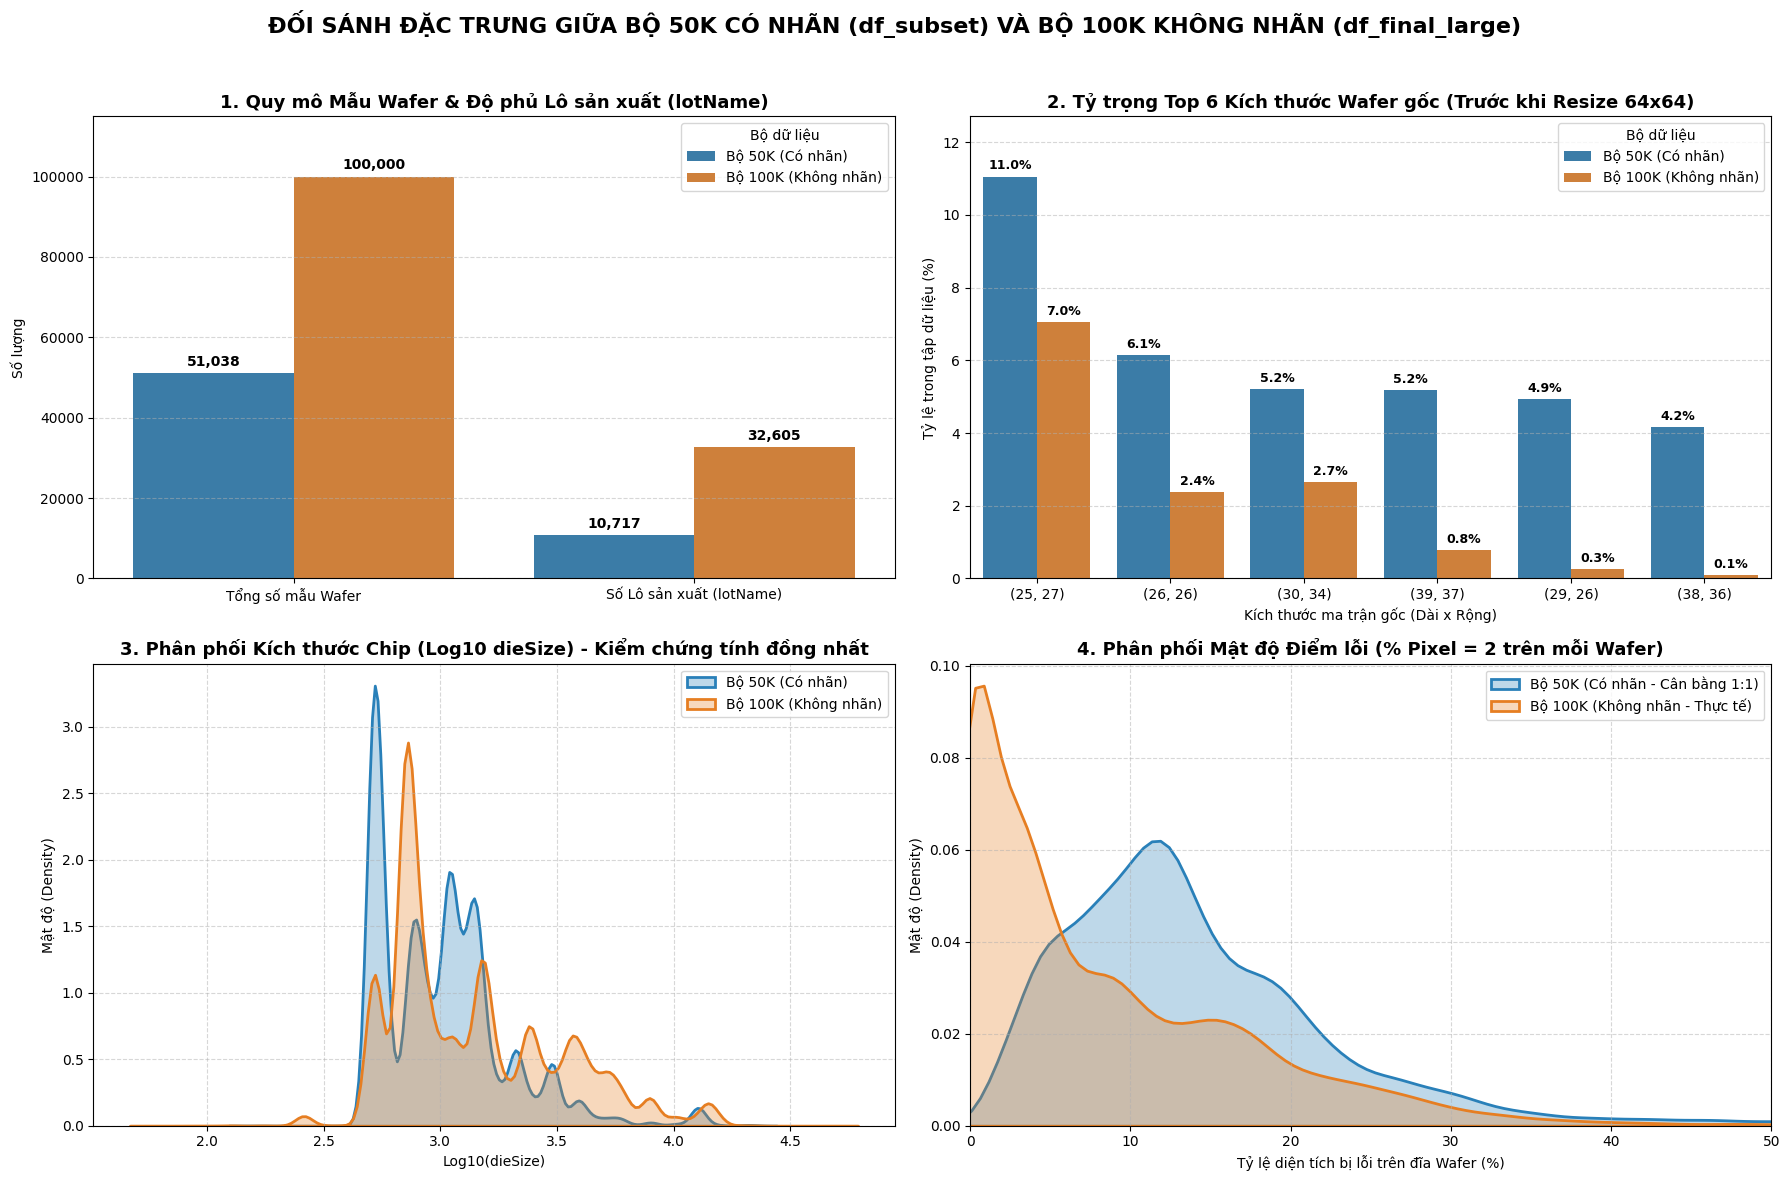

In [23]:
print("Đang tính toán các chỉ số vật lý để vẽ biểu đồ đối sánh 2 bộ dữ liệu (50K vs 100K)...")

# 1. Đảm bảo cột waferMapDim đã tồn tại ở cả 2 bộ
if 'waferMapDim' not in df_subset.columns:
    df_subset['waferMapDim'] = df_subset['waferMap'].apply(lambda x: x.shape)
if 'waferMapDim' not in df_final_large.columns:
    df_final_large['waferMapDim'] = df_final_large['waferMap'].apply(lambda x: x.shape)

# 2. Tính tỷ lệ pixel lỗi (giá trị = 2) trên tổng diện tích đĩa Wafer (giá trị > 0) cho cả 2 bộ
def calc_defect_density(wm):
    valid_px = np.sum(wm > 0)
    return (np.sum(wm == 2) / valid_px * 100) if valid_px > 0 else 0.0

df_subset['defect_density_pct'] = df_subset['waferMap_resized'].apply(calc_defect_density)
df_final_large['defect_density_pct'] = df_final_large['waferMap_resized'].apply(calc_defect_density)

# KHỞI TẠO DASHBOARD 4 BIỂU ĐỒ SO SÁNH (2 HÀNG x 2 CỘT)
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('ĐỐI SÁNH ĐẶC TRƯNG GIỮA BỘ 50K CÓ NHÃN (df_subset) VÀ BỘ 100K KHÔNG NHÃN (df_final_large)', 
             fontsize=16, fontweight='bold', y=0.98)

palette_compare = ['#2980b9', '#e67e22'] # Xanh dương (Bộ 50K) - Cam (Bộ 100K)

# BIỂU ĐỒ 1: SO SÁNH QUY MÔ MẪU WAFER & SỐ LÔ SẢN XUẤT (lotName)
ax1 = axes[0, 0]
scale_df = pd.DataFrame({
    'Chỉ số': ['Tổng số mẫu Wafer', 'Tổng số mẫu Wafer', 'Số Lô sản xuất (lotName)', 'Số Lô sản xuất (lotName)'],
    'Bộ dữ liệu': ['Bộ 50K (Có nhãn)', 'Bộ 100K (Không nhãn)', 'Bộ 50K (Có nhãn)', 'Bộ 100K (Không nhãn)'],
    'Số lượng': [
        len(df_subset), 
        len(df_final_large), 
        df_subset['lotName'].nunique(), 
        df_final_large['lotName'].nunique()
    ]
})

sns.barplot(data=scale_df, x='Chỉ số', y='Số lượng', hue='Bộ dữ liệu', palette=palette_compare, ax=ax1)
for container in ax1.containers:
    ax1.bar_label(container, fmt='{:,.0f}', padding=3, fontweight='bold', fontsize=10)
ax1.margins(y=0.15)
ax1.set_title('1. Quy mô Mẫu Wafer & Độ phủ Lô sản xuất (lotName)', fontsize=13, fontweight='bold')
ax1.set_xlabel('')
ax1.set_ylabel('Số lượng')
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# BIỂU ĐỒ 2: TOP 6 KÍCH THƯỚC MA TRẬN GỐC (waferMapDim) PHỔ BIẾN NHẤT (%)
ax2 = axes[0, 1]
top6_dims = df_subset['waferMapDim'].value_counts().head(6).index.tolist()

dim_50k_pct = (df_subset['waferMapDim'].value_counts(normalize=True).reindex(top6_dims).fillna(0) * 100).values
dim_100k_pct = (df_final_large['waferMapDim'].value_counts(normalize=True).reindex(top6_dims).fillna(0) * 100).values

dim_df = pd.DataFrame({
    'Kích thước gốc': [str(d) for d in top6_dims] * 2,
    'Tỷ lệ (%)': np.concatenate([dim_50k_pct, dim_100k_pct]),
    'Bộ dữ liệu': ['Bộ 50K (Có nhãn)'] * 6 + ['Bộ 100K (Không nhãn)'] * 6
})

sns.barplot(data=dim_df, x='Kích thước gốc', y='Tỷ lệ (%)', hue='Bộ dữ liệu', palette=palette_compare, ax=ax2)
for container in ax2.containers:
    ax2.bar_label(container, fmt='{:.1f}%', padding=3, fontweight='bold', fontsize=9)
ax2.margins(y=0.15)
ax2.set_title('2. Tỷ trọng Top 6 Kích thước Wafer gốc (Trước khi Resize 64x64)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Kích thước ma trận gốc (Dài x Rộng)')
ax2.set_ylabel('Tỷ lệ trong tập dữ liệu (%)')
ax2.grid(axis='y', linestyle='--', alpha=0.5)

# BIỂU ĐỒ 3: PHÂN PHỐI KÍCH THƯỚC CHIP (dieSize) TRÊN THANG LOG
ax3 = axes[1, 0]
sns.kdeplot(np.log10(df_subset['dieSize'].clip(lower=1)), label='Bộ 50K (Có nhãn)', 
            color=palette_compare[0], fill=True, alpha=0.3, linewidth=2, ax=ax3)
sns.kdeplot(np.log10(df_final_large['dieSize'].clip(lower=1)), label='Bộ 100K (Không nhãn)', 
            color=palette_compare[1], fill=True, alpha=0.3, linewidth=2, ax=ax3)

ax3.set_title('3. Phân phối Kích thước Chip (Log10 dieSize) - Kiểm chứng tính đồng nhất', fontsize=13, fontweight='bold')
ax3.set_xlabel('Log10(dieSize)')
ax3.set_ylabel('Mật độ (Density)')
ax3.legend()
ax3.grid(linestyle='--', alpha=0.5)

# BIỂU ĐỒ 4: SO SÁNH PHÂN PHỐI MẬT ĐỘ ĐIỂM LỖI (% PIXEL = 2 TRÊN ĐĨA WAFER)
ax4 = axes[1, 1]
sns.kdeplot(df_subset['defect_density_pct'], label='Bộ 50K (Có nhãn - Cân bằng 1:1)', 
            color=palette_compare[0], fill=True, alpha=0.3, linewidth=2, ax=ax4)
sns.kdeplot(df_final_large['defect_density_pct'], label='Bộ 100K (Không nhãn - Thực tế)', 
            color=palette_compare[1], fill=True, alpha=0.3, linewidth=2, ax=ax4)

ax4.set_xlim(0, 50)
ax4.set_title('4. Phân phối Mật độ Điểm lỗi (% Pixel = 2 trên mỗi Wafer)', fontsize=13, fontweight='bold')
ax4.set_xlabel('Tỷ lệ diện tích bị lỗi trên đĩa Wafer (%)')
ax4.set_ylabel('Mật độ (Density)')
ax4.legend()
ax4.grid(linestyle='--', alpha=0.5)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

**Biểu đồ chênh lệch dữ liệu (Trước và Sau khi cân bằng)**

Đang trực quan hóa sự mất cân bằng dữ liệu...


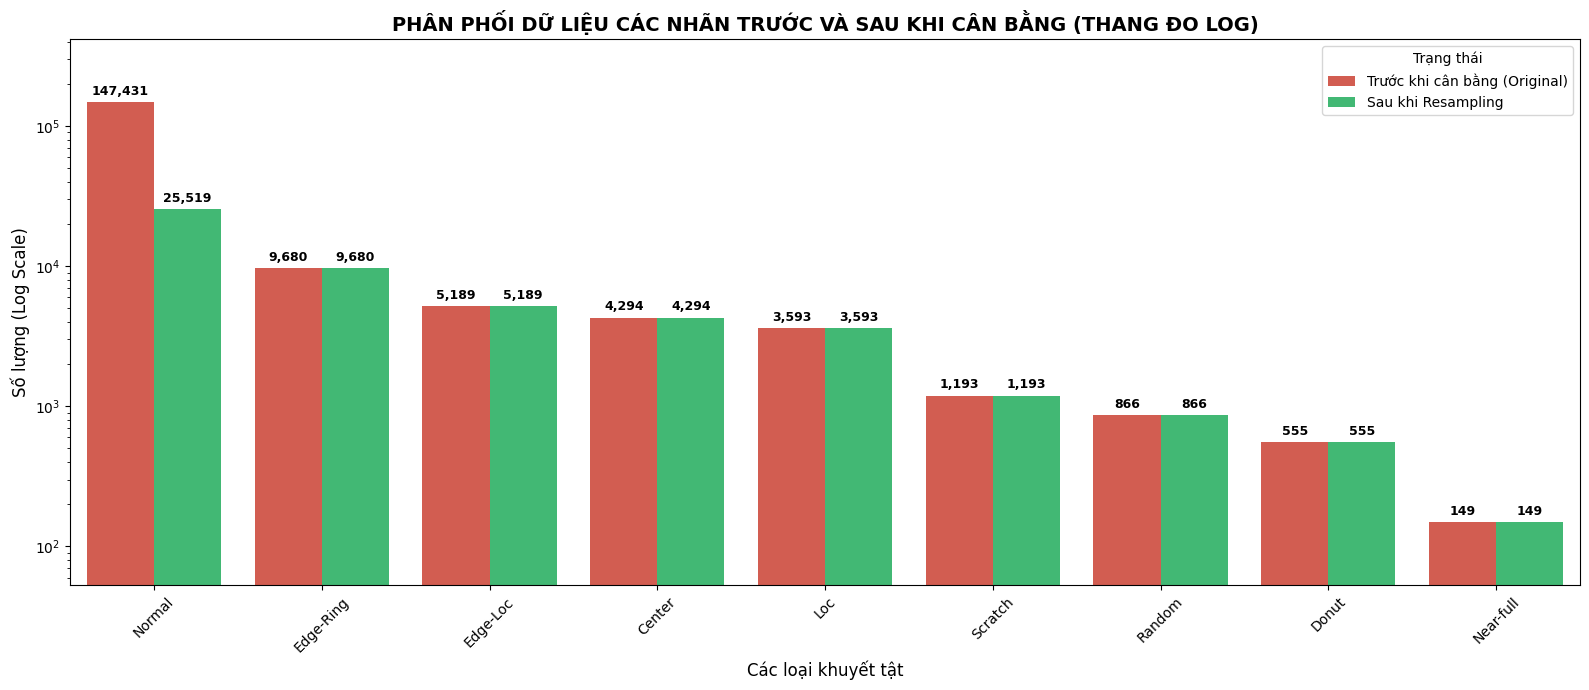

In [10]:
print("Đang trực quan hóa sự mất cân bằng dữ liệu...")
# Dữ liệu trước khi cân bằng (Từ df_labeled)
before_balance = df_labeled['failureType'].value_counts().reset_index()
before_balance.columns = ['Loại khuyết tật', 'Số lượng']
before_balance['Giai đoạn'] = 'Trước khi cân bằng (Original)'

# Dữ liệu sau khi cân bằng (Từ df_subset)
after_balance = df_subset['failureType'].value_counts().reset_index()
after_balance.columns = ['Loại khuyết tật', 'Số lượng']
after_balance['Giai đoạn'] = 'Sau khi Resampling'

# Gộp chung để vẽ biểu đồ nhóm
df_viz_balance = pd.concat([before_balance, after_balance])

plt.figure(figsize=(16, 7))
ax = sns.barplot(
    data=df_viz_balance, 
    x='Loại khuyết tật', 
    y='Số lượng', 
    hue='Giai đoạn', 
    palette=['#e74c3c', '#2ecc71']
)

plt.yscale('log')

for container in ax.containers:
    ax.bar_label(
        container, 
        fmt='{:,.0f}',
        padding=3,
        fontsize=9, 
        fontweight='bold'
    )

ax.margins(y=0.15)

plt.title('PHÂN PHỐI DỮ LIỆU CÁC NHÃN TRƯỚC VÀ SAU KHI CÂN BẰNG (THANG ĐO LOG)', fontsize=14, fontweight='bold')
plt.xlabel('Các loại khuyết tật', fontsize=12)
plt.ylabel('Số lượng (Log Scale)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Trạng thái', loc='upper right')
plt.tight_layout()
plt.show()

# **GIAI ĐOẠN 2: GIẢM CHIỀU (PCA) & GOM CỤM CƠ SỞ (K-MEANS + ĐỐI CHIẾU CHÉO)**

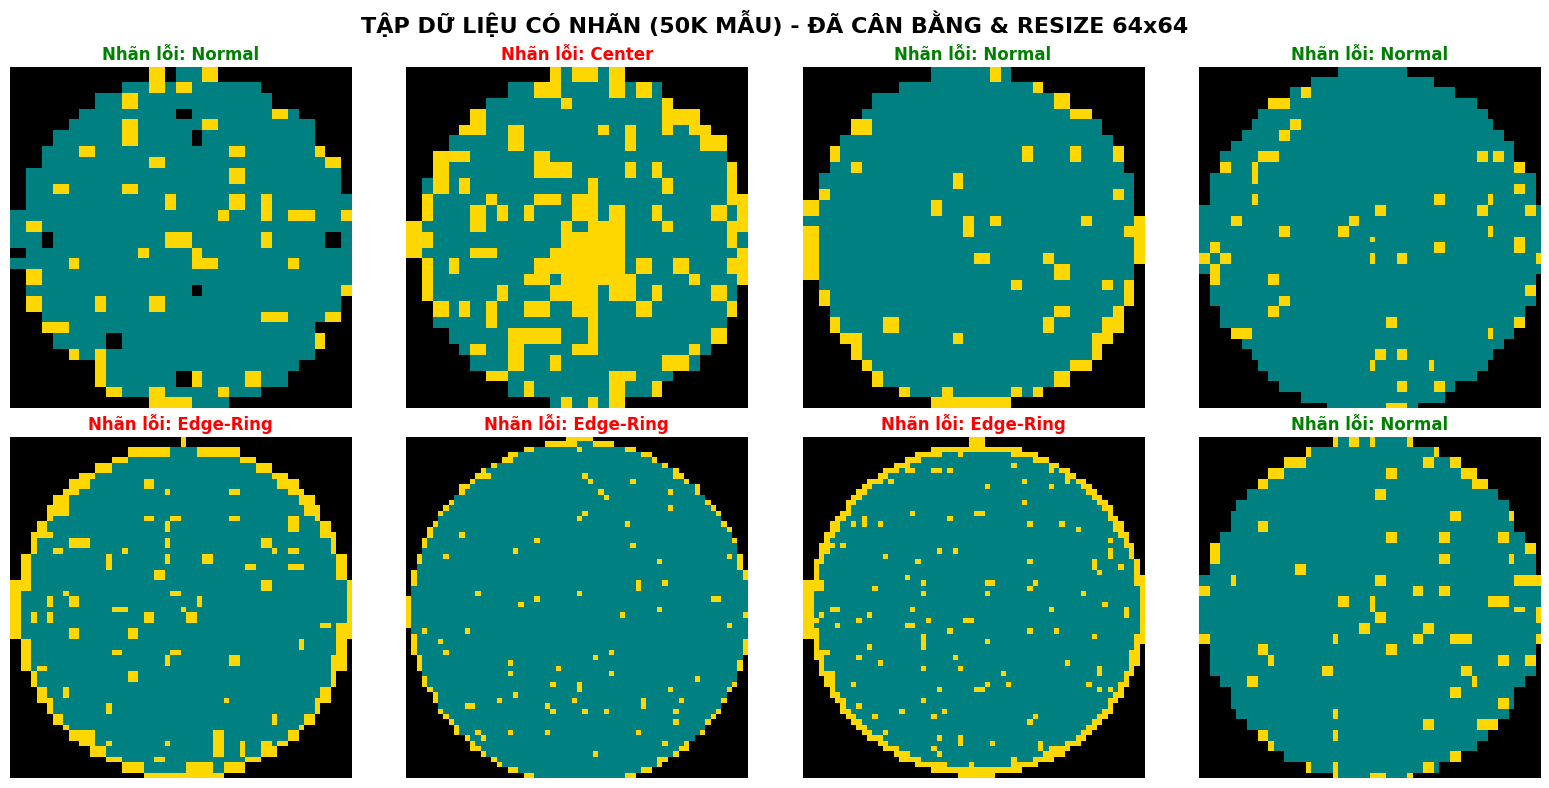


--------------------------------------------------------------------------------



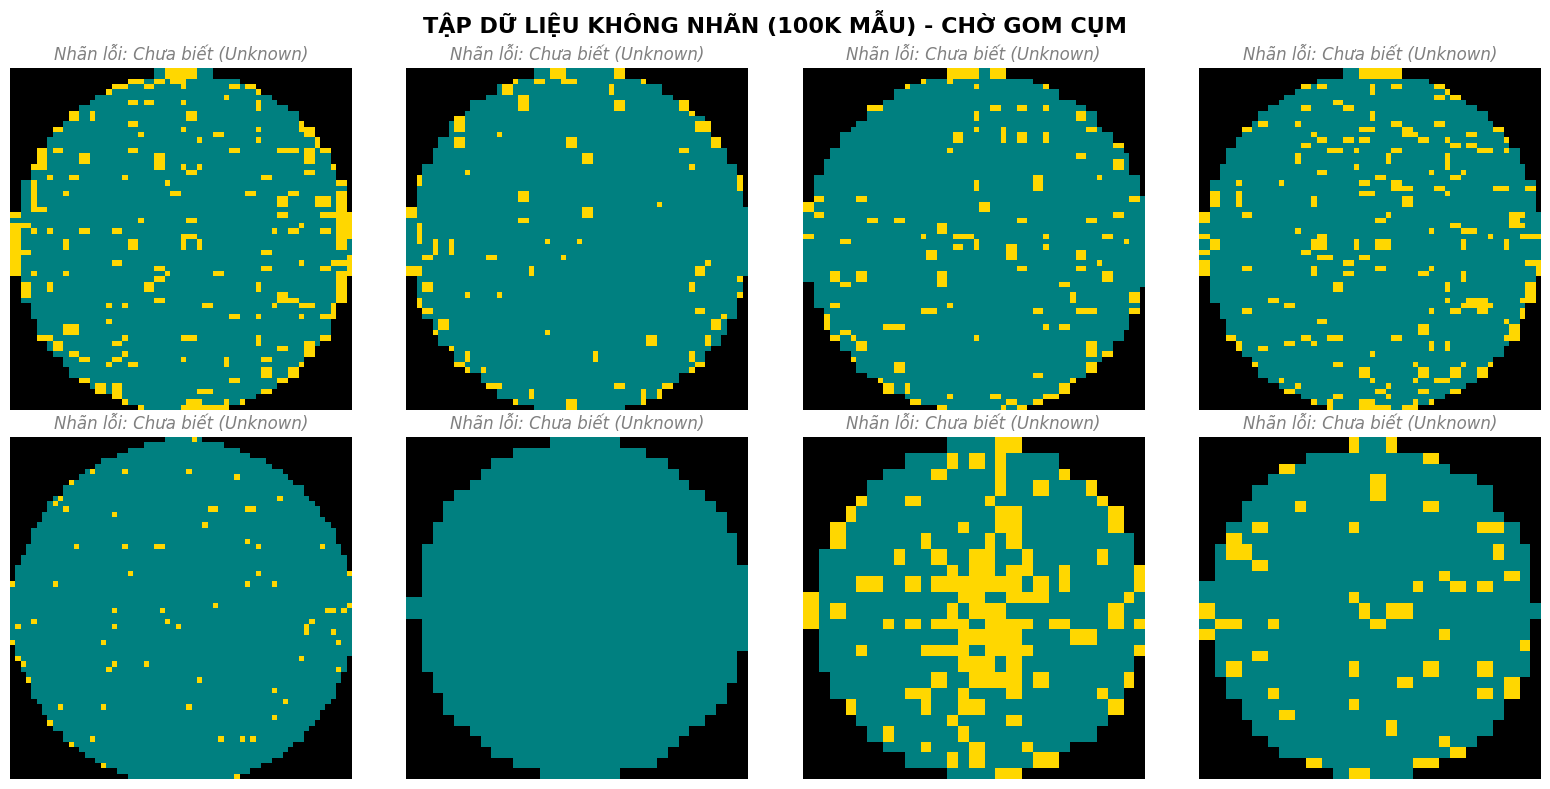

In [11]:
# Định nghĩa bảng màu trực quan: 0 (Đen), 1 (Xanh lơ), 2 (Vàng)
colors = ['black', 'teal', 'gold']
cmap = mcolors.ListedColormap(colors)

# 1. TRỰC QUAN HÓA TẬP CÓ NHÃN (SUBSET 50K)
fig1, axes1 = plt.subplots(2, 4, figsize=(16, 8))
fig1.suptitle('TẬP DỮ LIỆU CÓ NHÃN (50K MẪU) - ĐÃ CÂN BẰNG & RESIZE 64x64', fontsize=16, fontweight='bold')

# Bốc ngẫu nhiên 8 ảnh có nhãn để hiển thị
sample_labeled = df_subset.sample(8, random_state=42)

for i, ax in enumerate(axes1.flat):
    img = sample_labeled.iloc[i]['waferMap_resized']
    label = sample_labeled.iloc[i]['failureType']

    # Hiển thị ma trận 2D thành ảnh
    ax.imshow(img, cmap=cmap, vmin=0, vmax=2)
    ax.set_title(f"Nhãn lỗi: {label}", fontsize=12, fontweight='bold', color='red' if label != 'Normal' else 'green')
    ax.axis('off') # Tắt trục tọa độ cho đẹp

plt.tight_layout()
plt.show()

print("\n" + "-"*80 + "\n")

# 2. TRỰC QUAN HÓA TẬP KHÔNG NHÃN (TẬP LỚN 100K)
fig2, axes2 = plt.subplots(2, 4, figsize=(16, 8))
fig2.suptitle('TẬP DỮ LIỆU KHÔNG NHÃN (100K MẪU) - CHỜ GOM CỤM', fontsize=16, fontweight='bold')

# Bốc ngẫu nhiên 8 ảnh không nhãn
sample_unlabeled = df_final_large.sample(8, random_state=99)

for i, ax in enumerate(axes2.flat):
    img = sample_unlabeled.iloc[i]['waferMap_resized']

    ax.imshow(img, cmap=cmap, vmin=0, vmax=2)
    ax.set_title("Nhãn lỗi: Chưa biết (Unknown)", fontsize=12, style='italic', color='gray')
    ax.axis('off')

plt.tight_layout()
plt.show()

**Trích xuất đặc trưng**

In [12]:
# BƯỚC 1: CHUẨN BỊ DỮ LIỆU ĐẦU VÀO TỪ TẬP 100K KHÔNG NHÃN
print("Đang chuẩn bị dữ liệu ảnh...")
# Duỗi thẳng ma trận 2D (64x64) thành vector 1D (4096 chiều) để chạy PCA
X_unlabeled_flat = np.array([wm.flatten() for wm in df_final_large['waferMap_resized'].values], dtype=np.float32)

print(f"Kích thước ma trận phẳng đầu vào: {X_unlabeled_flat.shape}")

# BƯỚC 2 & 3: SỬ DỤNG PCA THAY CHO AUTOENCODER ĐỂ NÉN ĐẶC TRƯNG
print("\nĐang tiến hành giảm chiều dữ liệu xuống 128 chiều bằng PCA (Siêu tốc trên CPU)...")

# Khởi tạo mô hình PCA với 128 thành phần chính (đồng bộ số chiều embedding)
pca = PCA(n_components=128, random_state=42)

# Khớp và biến đổi toàn bộ 100.000 ảnh không nhãn
features_100k = pca.fit_transform(X_unlabeled_flat)

print(f"\nTHÀNH CÔNG: Kích thước dữ liệu sau khi nén: {features_100k.shape}")
# Kết quả in ra sẽ là: (100000, 128)

Đang chuẩn bị dữ liệu ảnh...
Kích thước ma trận phẳng đầu vào: (100000, 4096)

Đang tiến hành giảm chiều dữ liệu xuống 128 chiều bằng PCA (Siêu tốc trên CPU)...

THÀNH CÔNG: Kích thước dữ liệu sau khi nén: (100000, 128)


**Biểu đồ Phương sai tích lũy PCA (PCA Explained Variance Curve)**

Đang tính toán phân bố phương sai của các chiều PCA...


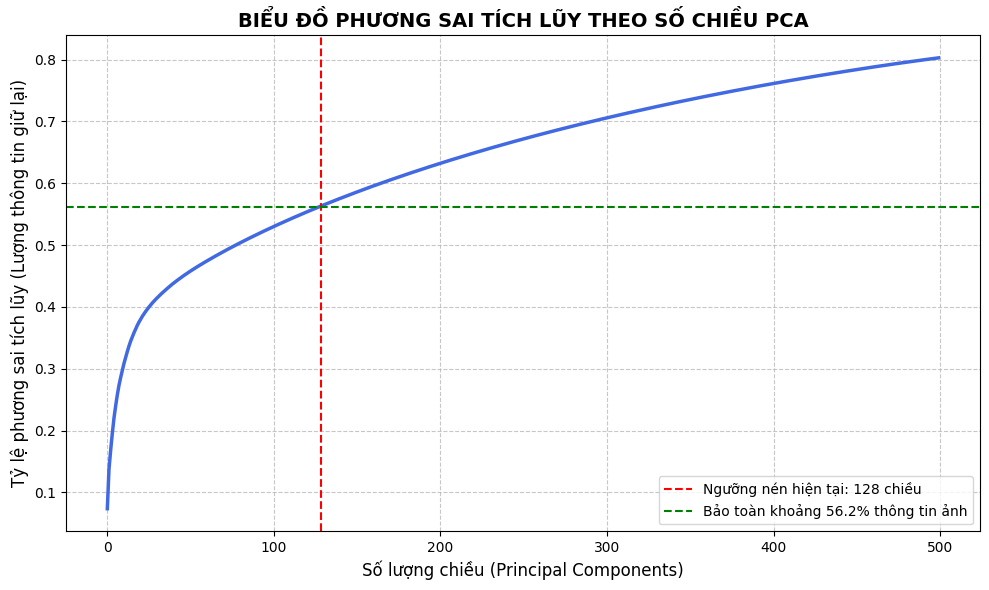

In [14]:
print("Đang tính toán phân bố phương sai của các chiều PCA...")

# 1. TẠO BIẾN X_sample_flat: Lấy ngẫu nhiên 3000 ảnh từ df_subset để tính toán (tránh tràn RAM Kaggle)
sample_data = df_subset.sample(n=min(3000, len(df_subset)), random_state=42)

# Ép ma trận ảnh 64x64 thành vector 1 chiều (4096 chiều) để đưa vào PCA
X_sample_flat = np.array([wm.flatten() for wm in sample_data['waferMap_resized'].values])

# 2. CHẠY PCA: Thử nghiệm tới 500 chiều thay vì 4096 để tiết kiệm thời gian
pca_full = PCA(n_components=500, random_state=42) 
pca_full.fit(X_sample_flat) 
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

# 3. VẼ BIỂU ĐỒ
plt.figure(figsize=(10, 6))
plt.plot(cumulative_variance, color='royalblue', linewidth=2.5)

# Đánh dấu vị trí 128 chiều mà nhóm đang sử dụng
plt.axvline(x=128, color='red', linestyle='--', label='Ngưỡng nén hiện tại: 128 chiều')
plt.axhline(y=cumulative_variance[127], color='green', linestyle='--', 
            label=f'Bảo toàn khoảng {cumulative_variance[127]*100:.1f}% thông tin ảnh')

plt.title('BIỂU ĐỒ PHƯƠNG SAI TÍCH LŨY THEO SỐ CHIỀU PCA', fontsize=14, fontweight='bold')
plt.xlabel('Số lượng chiều (Principal Components)', fontsize=12)
plt.ylabel('Tỷ lệ phương sai tích lũy (Lượng thông tin giữ lại)', fontsize=12)
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Tìm số cụm tối ưu (Elbow Method) & Phân cụm K-Means**

Đang chạy thử nghiệm nhiều kịch bản gom cụm để tìm số cụm (K) tối ưu...
Đã test xong k = 5 cụm
Đã test xong k = 6 cụm
Đã test xong k = 7 cụm
Đã test xong k = 8 cụm
Đã test xong k = 9 cụm
Đã test xong k = 10 cụm
Đã test xong k = 11 cụm
Đã test xong k = 12 cụm
Đã test xong k = 13 cụm
Đã test xong k = 14 cụm
Đã test xong k = 15 cụm
Đã test xong k = 16 cụm
Đã test xong k = 17 cụm
Đã test xong k = 18 cụm
Đã test xong k = 19 cụm
Đã test xong k = 20 cụm
Đã test xong k = 21 cụm
Đã test xong k = 22 cụm
Đã test xong k = 23 cụm
Đã test xong k = 24 cụm
Đã test xong k = 25 cụm


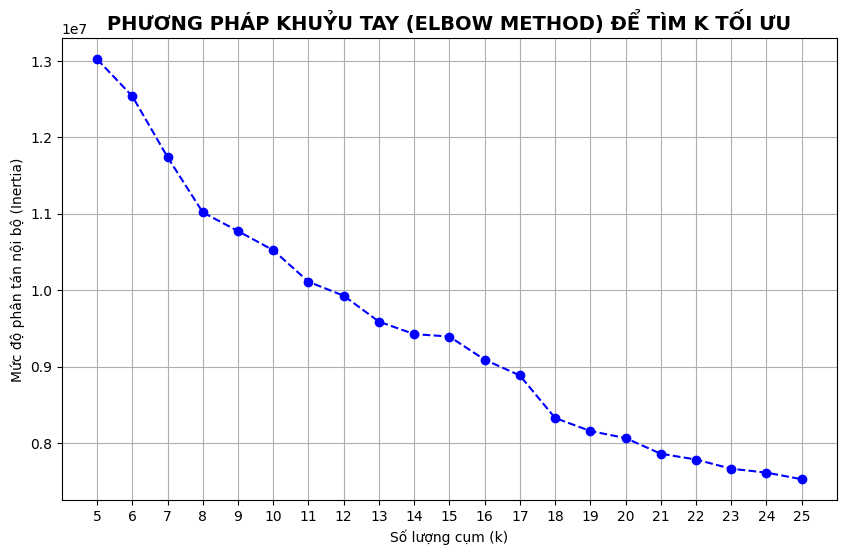

In [15]:
print("Đang chạy thử nghiệm nhiều kịch bản gom cụm để tìm số cụm (K) tối ưu...")

# Thử nghiệm chia từ 5 cụm đến 25 cụm
k_values = range(5, 26)
inertia_values = []

for k in k_values:
    # Dùng MiniBatchKMeans để xử lý siêu tốc dữ liệu lớn
    kmeans = MiniBatchKMeans(n_clusters=k, random_state=42, batch_size=2048)
    kmeans.fit(features_100k)
    inertia_values.append(kmeans.inertia_)
    print(f"Đã test xong k = {k} cụm")

# Vẽ biểu đồ Khuỷu tay (Elbow Curve)
plt.figure(figsize=(10, 6))
plt.plot(k_values, inertia_values, marker='o', linestyle='--', color='b')
plt.title('PHƯƠNG PHÁP KHUỶU TAY (ELBOW METHOD) ĐỂ TÌM K TỐI ƯU', fontsize=14, fontweight='bold')
plt.xlabel('Số lượng cụm (k)')
plt.ylabel('Mức độ phân tán nội bộ (Inertia)')
plt.xticks(k_values)
plt.grid(True)
plt.show()

**K = 18 tối ưu nhất**

Đang tiến hành phân lô 100.000 ảnh vào 18 cụm...
Đã dán nhãn cụm xong cho toàn bộ dữ liệu!

--- SỐ LƯỢNG ẢNH TRONG TỪNG CỤM ---
Cluster_Label
0      2318
1     15330
2      5030
3      6044
4     10574
5       885
6      3242
7      3802
8      1888
9      3095
10     2657
11      710
12    19564
13      375
14     5259
15     7562
16     3405
17     8260
Name: count, dtype: int64

Đang xuất ảnh để nghiệm thu bằng mắt thường (Domain Evaluation)...


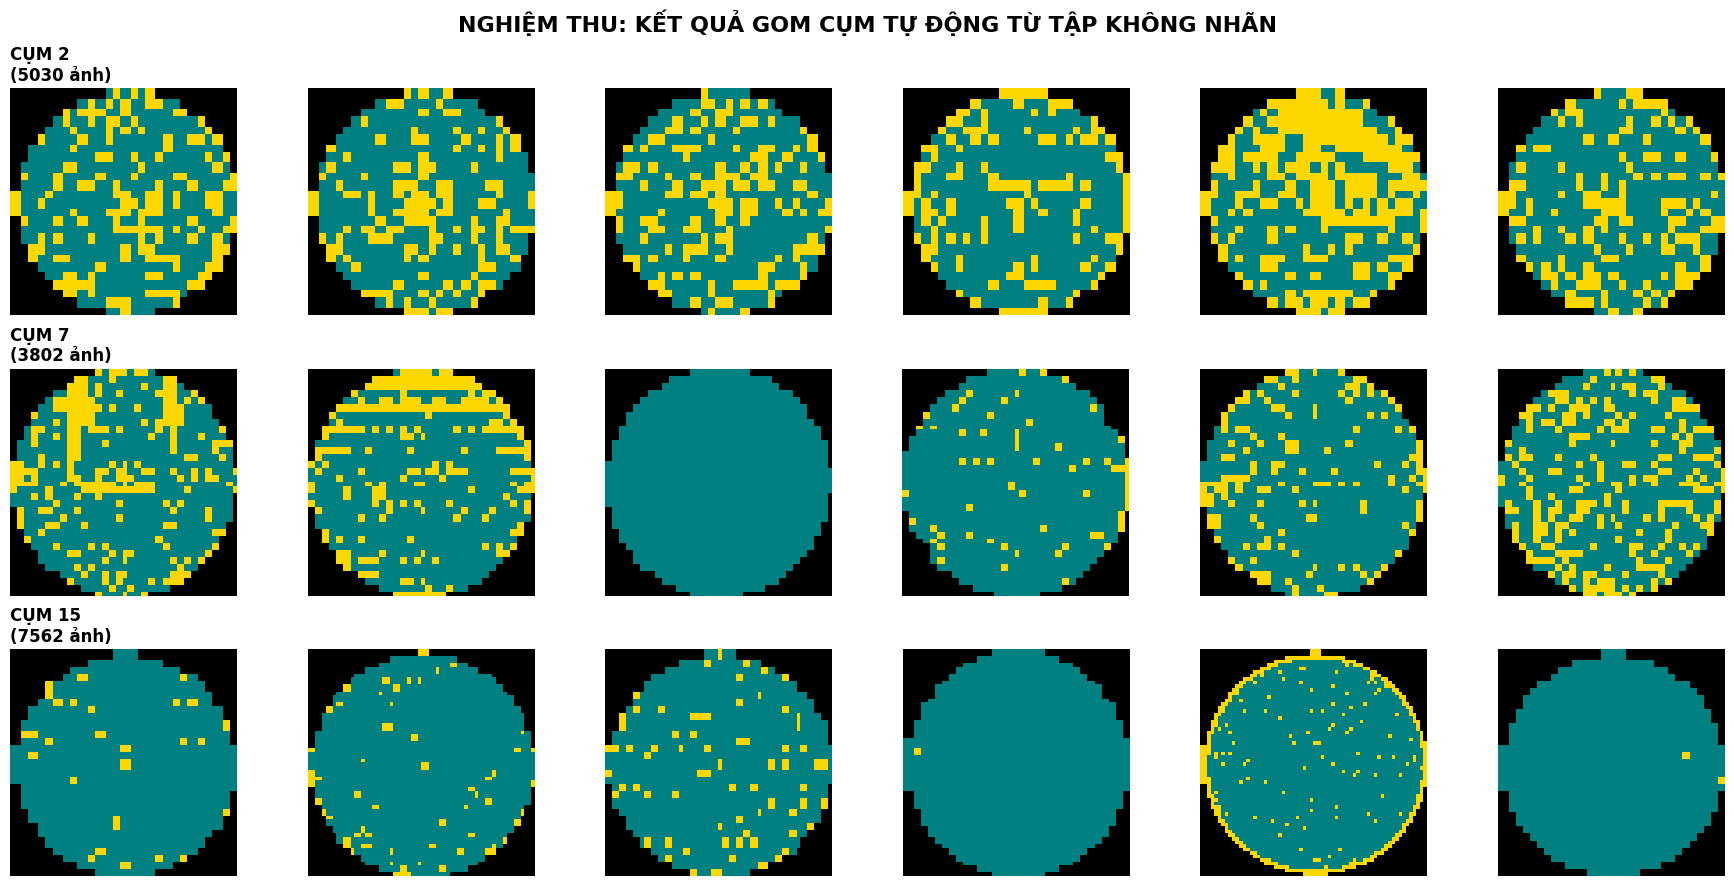

In [16]:
# BƯỚC 1: CHẠY GOM CỤM CHÍNH THỨC VỚI K = 18
OPTIMAL_K = 18
print(f"Đang tiến hành phân lô 100.000 ảnh vào {OPTIMAL_K} cụm...")

# Chạy K-Means với k=18
kmeans_final = MiniBatchKMeans(n_clusters=OPTIMAL_K, random_state=42, batch_size=2048)
# Dùng biến features_100k (từ AutoEncoder) hoặc features_100k_pca tùy bạn đang giữ trên RAM
cluster_labels = kmeans_final.fit_predict(features_100k)

# Dùng .copy() để biến df_final_large thành một thực thể độc lập hoàn toàn
df_final_large = df_final_large.copy()
df_final_large['Cluster_Label'] = cluster_labels
# Gắn nhãn cụm (Cluster_0, Cluster_1...) ngược lại vào DataFrame để dễ theo dõi
df_final_large['Cluster_Label'] = cluster_labels
print("Đã dán nhãn cụm xong cho toàn bộ dữ liệu!")

# Kiểm tra xem mỗi cụm đang gom được bao nhiêu ảnh
print("\n--- SỐ LƯỢNG ẢNH TRONG TỪNG CỤM ---")
print(df_final_large['Cluster_Label'].value_counts().sort_index())

# BƯỚC 2: TRỰC QUAN HÓA NGẪU NHIÊN 3 CỤM ĐỂ TÌM "LỖI LẠ"
print("\nĐang xuất ảnh để nghiệm thu bằng mắt thường (Domain Evaluation)...")

colors = ['black', 'teal', 'gold']
cmap = mcolors.ListedColormap(colors)

# Chọn ngẫu nhiên 3 cụm để show (Bạn có thể đổi số khác từ 0 đến 17 để xem các cụm khác)
clusters_to_view = [2, 7, 15]

fig, axes = plt.subplots(len(clusters_to_view), 6, figsize=(18, 3 * len(clusters_to_view)))
fig.suptitle('NGHIỆM THU: KẾT QUẢ GOM CỤM TỰ ĐỘNG TỪ TẬP KHÔNG NHÃN', fontsize=16, fontweight='bold')

for row_idx, cluster_id in enumerate(clusters_to_view):
    # Lọc ra các ảnh thuộc cụm tương ứng
    cluster_data = df_final_large[df_final_large['Cluster_Label'] == cluster_id]

    # Bốc ngẫu nhiên 6 ảnh trong cụm đó để hiển thị
    sample_imgs = cluster_data.sample(6, random_state=42)['waferMap_resized'].values

    for col_idx in range(6):
        ax = axes[row_idx, col_idx]
        ax.imshow(sample_imgs[col_idx], cmap=cmap, vmin=0, vmax=2)
        ax.axis('off')
        if col_idx == 0:
            ax.set_title(f"CỤM {cluster_id} \n({len(cluster_data)} ảnh)", fontsize=12, fontweight='bold', loc='left')

plt.tight_layout()
plt.show()

# **GIAI ĐOẠN 3: HỌC CÓ GIÁM SÁT - MÔ HÌNH BASELINE CNN (VERSION 1.0 - 9 CLASSES)**

**Đối chiếu chéo (Cross-Analysis) để tìm hình thái lỗi mới**

In [17]:
print("1. Đang duỗi phẳng tập 50k ảnh để phù hợp với thuật toán PCA...")
# Dùng lại df_subset chứa tập có nhãn để flatten
X_labeled_flat = np.array([wm.flatten() for wm in df_subset['waferMap_resized'].values], dtype=np.float32)

print("2. Đang nén tập 50k bằng mô hình PCA đã huấn luyện trước đó...")
# Thay thế encoder.predict() bằng pca.transform()
features_50k_pca = pca.transform(X_labeled_flat)

print("3. Phân bổ 50k ảnh vào 18 cụm của mô hình K-Means...")
df_subset['Cluster_Label'] = kmeans_final.predict(features_50k_pca)

print("\n Hoàn tất việc gán cụm cho tập 50k ảnh có nhãn!")

1. Đang duỗi phẳng tập 50k ảnh để phù hợp với thuật toán PCA...
2. Đang nén tập 50k bằng mô hình PCA đã huấn luyện trước đó...
3. Phân bổ 50k ảnh vào 18 cụm của mô hình K-Means...

 Hoàn tất việc gán cụm cho tập 50k ảnh có nhãn!


**Chuẩn bị dữ liệu & Huấn luyện CNN Version 1.0 (9 Nhãn)**

In [19]:
# 1. Mã hóa nhãn chữ thành số (0 -> 8)
le = LabelEncoder()
y_labeled = le.fit_transform(df_subset['failureType'])

# 2. Chuẩn hóa ma trận ảnh đầu vào về [0, 1]
X_labeled = np.stack(df_subset['waferMap_resized'].values).astype('float32') / 2.0
X_labeled = np.expand_dims(X_labeled, axis=-1)

# 3. Tách tập Train / Test (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X_labeled, y_labeled, test_size=0.2, random_state=42, stratify=y_labeled
)

# 4. Tính Class Weights đã làm mượt (Square-Root Smoothing) để chống giật đồ thị Validation
raw_weights = class_weight.compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
smooth_weights = np.clip(np.sqrt(raw_weights), 0.5, 5.0)
class_weight_dict = dict(enumerate(smooth_weights))

print("Trọng số các lớp sau khi làm mượt:")
for cls_name, w_raw, w_smooth in zip(le.classes_, raw_weights, smooth_weights):
    print(f" - {cls_name:<12}: Gốc = {w_raw:6.2f}  -->  Làm mượt = {w_smooth:.2f}")

# 5. Khởi tạo kiến trúc CNN (bổ sung BatchNormalization để hội tụ mượt mà)
def build_cnn_model(num_classes):
    m = models.Sequential([
        layers.Input(shape=(64, 64, 1)),
        
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.4),
        layers.Dense(num_classes, activation='softmax')
    ])
    m.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return m

# 6. Thiết lập Callbacks tự động giảm Learning Rate khi chững lại và lưu Epoch tốt nhất
callbacks_list = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
    EarlyStopping(monitor='val_accuracy', patience=4, restore_best_weights=True, verbose=1)
]

model = build_cnn_model(num_classes=9)
print("\nBắt đầu huấn luyện CNN Version 1.0 (9 Classes)...")
history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=128,
    validation_data=(X_test, y_test),
    class_weight=class_weight_dict,
    callbacks=callbacks_list
)

Bắt đầu huấn luyện CNN Version 1.0 (9 Classes)...
Epoch 1/10
319/319 ━━━━━━━━━━━━━━━━━━━━ 138s 427ms/step - accuracy: 0.4559 - loss: 1.3334 - val_accuracy: 0.6474 - val_loss: 1.0394
Epoch 2/10
319/319 ━━━━━━━━━━━━━━━━━━━━ 133s 416ms/step - accuracy: 0.6168 - loss: 0.8207 - val_accuracy: 0.5903 - val_loss: 0.9800
Epoch 3/10
319/319 ━━━━━━━━━━━━━━━━━━━━ 132s 414ms/step - accuracy: 0.6606 - loss: 0.7186 - val_accuracy: 0.8155 - val_loss: 0.6986
Epoch 4/10
319/319 ━━━━━━━━━━━━━━━━━━━━ 131s 411ms/step - accuracy: 0.6835 - loss: 0.6623 - val_accuracy: 0.7013 - val_loss: 0.8022
Epoch 5/10
319/319 ━━━━━━━━━━━━━━━━━━━━ 143s 447ms/step - accuracy: 0.7190 - loss: 0.5668 - val_accuracy: 0.7159 - val_loss: 0.7600
Epoch 6/10
319/319 ━━━━━━━━━━━━━━━━━━━━ 138s 430ms/step - accuracy: 0.7436 - loss: 0.5101 - val_accuracy: 0.6243 - val_loss: 0.8686
Epoch 7/10
319/319 ━━━━━━━━━━━━━━━━━━━━ 131s 411ms/step - accuracy: 0.7718 - loss: 0.4620 - val_accuracy: 0.8195 - val_loss: 0.5733
Epoch 8/10
319/319 ━━━━━━━

**Đánh giá toàn diện CNN Version 1.0**

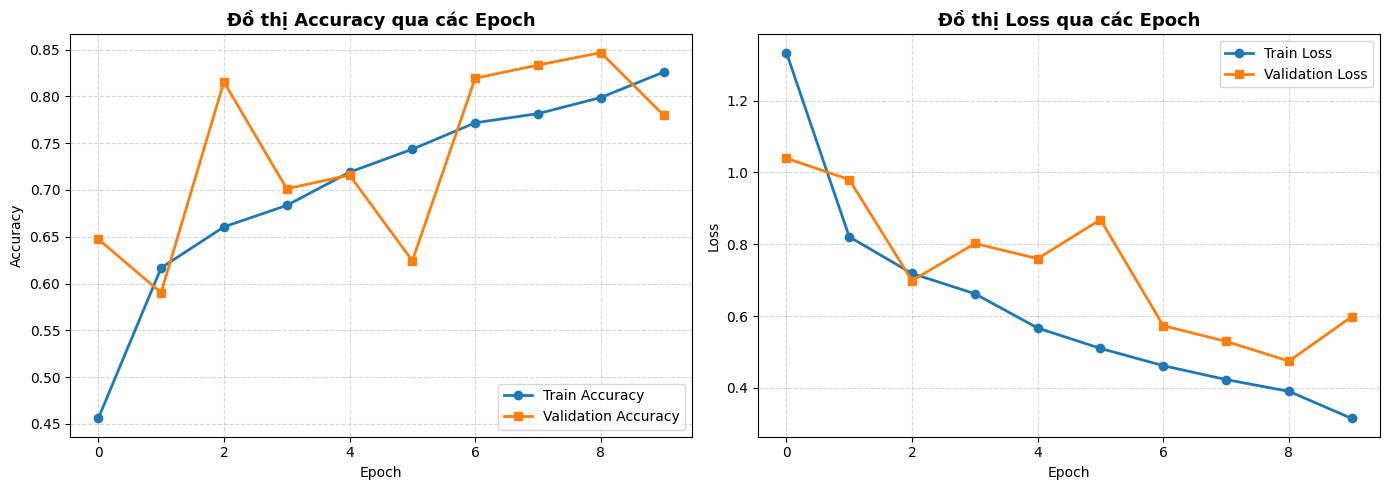


=== BẢNG BÁO CÁO PHÂN LOẠI CHI TIẾT (ĐỘ CHÍNH XÁC TỔNG THỂ: 84.97%) ===


,Precision (Độ chuẩn xác),Recall (Độ phủ),F1-Score (Điểm cân bằng),Số lượng mẫu (Support)
Nhãn khuyết tật (Class),,,,
Center,0.9043,0.9243,0.9142,859
Donut,0.7778,0.8829,0.8270,111
Edge-Loc,0.6635,0.7977,0.7244,"1,038"
Edge-Ring,0.9711,0.9721,0.9716,"1,936"
Loc,0.5106,0.5355,0.5227,719
Near-full,0.8438,0.9000,0.8710,30
Normal,0.9245,0.8658,0.8942,"5,104"
Random,0.8947,0.8844,0.8895,173
Scratch,0.3132,0.3697,0.3391,238


In [26]:
# 1. VẼ BIỂU ĐỒ THEO DÕI OVERFITTING (CÓ LƯỚI & ĐÁNH DẤU ĐIỂM)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history['accuracy'], marker='o', linewidth=2, label='Train Accuracy')
ax1.plot(history.history['val_accuracy'], marker='s', linewidth=2, label='Validation Accuracy')
ax1.set_title('Đồ thị Accuracy qua các Epoch', fontsize=13, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

ax2.plot(history.history['loss'], marker='o', linewidth=2, label='Train Loss')
ax2.plot(history.history['val_loss'], marker='s', linewidth=2, label='Validation Loss')
ax2.set_title('Đồ thị Loss qua các Epoch', fontsize=13, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

# 2. KẺ BẢNG BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT TABLE)
y_pred_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Xuất report dưới dạng Dictionary rồi chuyển thành DataFrame
report_dict = classification_report(y_test, y_pred, target_names=le.classes_, output_dict=True)
df_report = pd.DataFrame(report_dict).transpose()

# Tách giá trị Accuracy tổng thể ra để in tiêu đề cho gọn, vì dòng 'accuracy' trong bảng gốc bị lệch cột
overall_acc = report_dict['accuracy'] * 100
df_report = df_report.drop(index='accuracy')

# Đổi tên cột và dòng tổng kết sang Tiếng Việt cho chuyên nghiệp
df_report.columns = ['Precision (Độ chuẩn xác)', 'Recall (Độ phủ)', 'F1-Score (Điểm cân bằng)', 'Số lượng mẫu (Support)']
df_report = df_report.rename(index={
    'macro avg': 'Trung bình đều (Macro Avg)',
    'weighted avg': 'Trung bình trọng số (Weighted Avg)'
})
df_report.index.name = 'Nhãn khuyết tật (Class)'

# Định dạng kẻ bảng có viền và tô màu tự động theo điểm số (Xanh đậm = Cao, Vàng nhạt = Thấp)
styled_report = (
    df_report.style
    .format({
        'Precision (Độ chuẩn xác)': '{:.4f}',
        'Recall (Độ phủ)': '{:.4f}',
        'F1-Score (Điểm cân bằng)': '{:.4f}',
        'Số lượng mẫu (Support)': '{:,.0f}'
    })
    .background_gradient(
        cmap='YlGn', 
        subset=['Precision (Độ chuẩn xác)', 'Recall (Độ phủ)', 'F1-Score (Điểm cân bằng)'],
        vmin=0.5, vmax=1.0
    )
    .set_properties(**{
        'border': '1px solid #bdc3c7',
        'text-align': 'center',
        'padding': '8px'
    })
    .set_table_styles([
        {'selector': 'th', 'props': [
            ('background-color', '#2c3e50'), 
            ('color', 'white'), 
            ('font-weight', 'bold'),
            ('text-align', 'center'),
            ('border', '1px solid #bdc3c7'),
            ('padding', '8px')
        ]}
    ])
)

print(f"\n=== BẢNG BÁO CÁO PHÂN LOẠI CHI TIẾT (ĐỘ CHÍNH XÁC TỔNG THỂ: {overall_acc:.2f}%) ===")
display(styled_report)

**Biểu đồ So sánh Điểm F1-Score (Hiệu suất từng nhãn)**

Đang trực quan hóa biểu đồ F1-Score cho từng class...


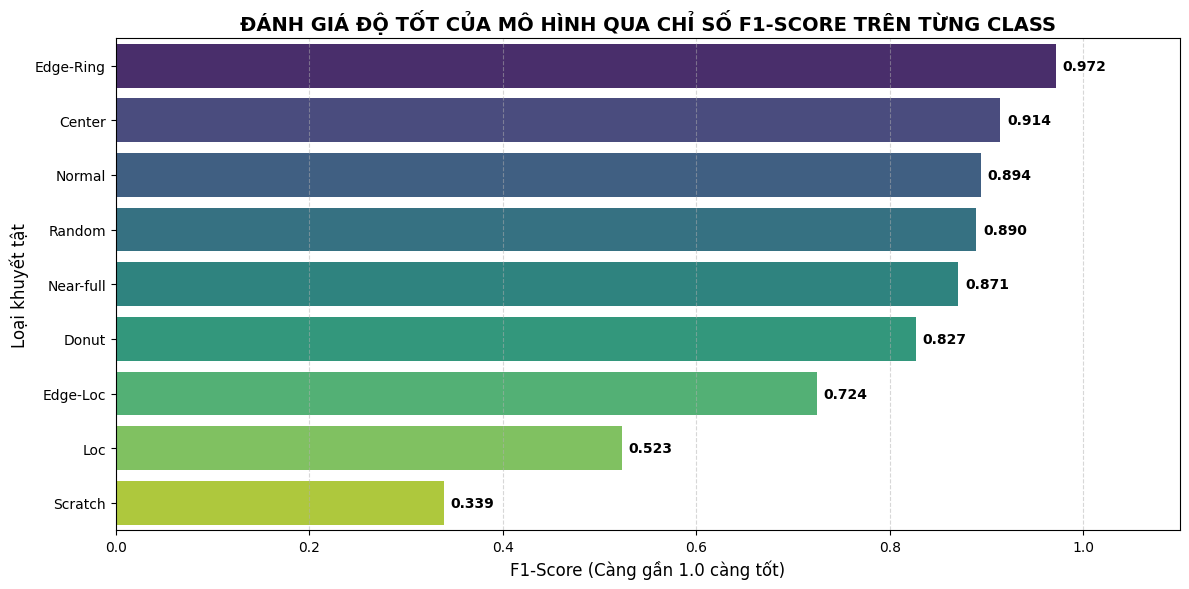

In [28]:
print("Đang trực quan hóa biểu đồ F1-Score cho từng class...")

# Lấy dữ liệu báo cáo dạng Dictionary
y_pred = np.argmax(y_pred_probs, axis=1)
report_dict = classification_report(y_test, y_pred, target_names=le.classes_, output_dict=True)

# Trích xuất riêng F1-Score của các class (loại bỏ các dòng tính tổng chung như accuracy, macro avg)
f1_scores = {key: val['f1-score'] for key, val in report_dict.items() if key in le.classes_}
df_f1 = pd.DataFrame(list(f1_scores.items()), columns=['Khuyết tật', 'F1-Score']).sort_values(by='F1-Score', ascending=False)

plt.figure(figsize=(12, 6))
ax = sns.barplot(x='F1-Score', y='Khuyết tật', data=df_f1, hue='Khuyết tật', palette='viridis', legend=False)
# Thêm con số chính xác lên từng cột
for p in ax.patches:
    ax.annotate(f"{p.get_width():.3f}", 
                (p.get_width(), p.get_y() + p.get_height() / 2.), 
                ha='left', va='center', 
                xytext=(5, 0), 
                textcoords='offset points',
                fontweight='bold')

plt.xlim(0, 1.1)
plt.title('ĐÁNH GIÁ ĐỘ TỐT CỦA MÔ HÌNH QUA CHỈ SỐ F1-SCORE TRÊN TỪNG CLASS', fontsize=14, fontweight='bold')
plt.xlabel('F1-Score (Càng gần 1.0 càng tốt)', fontsize=12)
plt.ylabel('Loại khuyết tật', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Xuất Ma trận nhầm lẫn (Confusion Matrix)**

319/319 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step


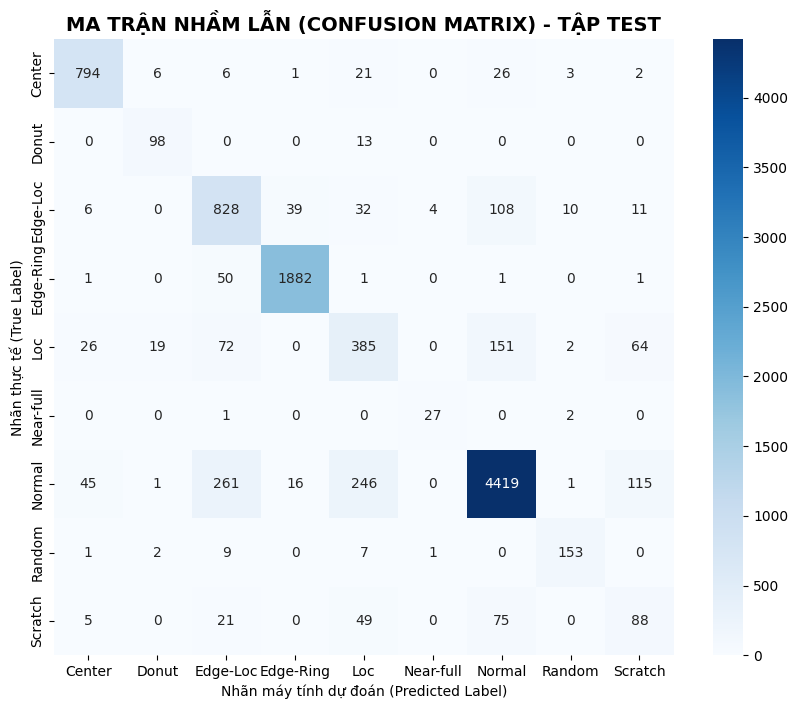

In [29]:
# Dự đoán trên tập Test
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1) 

# Vẽ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('MA TRẬN NHẦM LẪN (CONFUSION MATRIX) - TẬP TEST', fontsize=14, fontweight='bold')
plt.ylabel('Nhãn thực tế (True Label)')
plt.xlabel('Nhãn máy tính dự đoán (Predicted Label)')
plt.show()

**Biểu đồ ROC Đa lớp (Multiclass ROC & AUC)**

Đang vẽ biểu đồ đường cong ROC Đa lớp (Multiclass ROC)...
319/319 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step


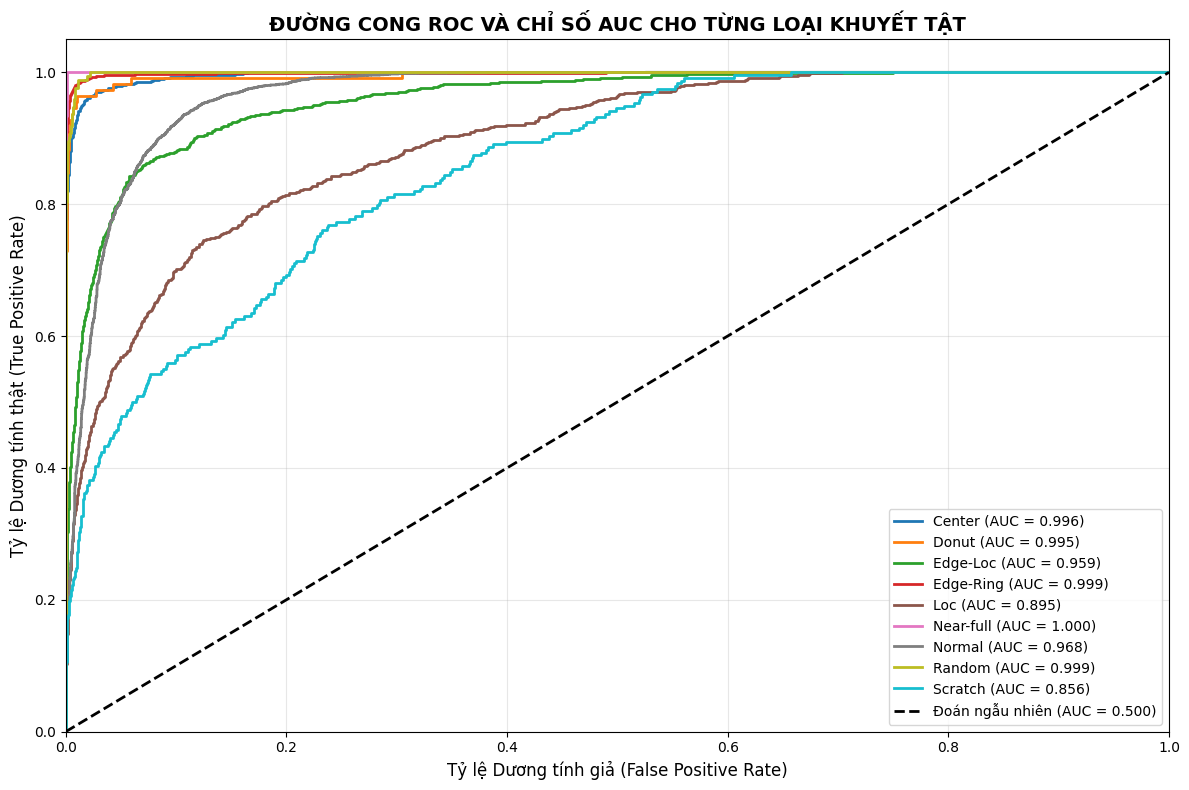

In [30]:
print("Đang vẽ biểu đồ đường cong ROC Đa lớp (Multiclass ROC)...")

# Dự đoán xác suất trên tập Test
y_pred_probs = model.predict(X_test)
# Binarize nhãn thực tế để vẽ ROC cho từng class
y_test_bin = label_binarize(y_test, classes=range(len(le.classes_)))
n_classes = len(le.classes_)

plt.figure(figsize=(12, 8))
colors = plt.cm.tab10(np.linspace(0, 1, n_classes))

for i, color in zip(range(n_classes), colors):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_probs[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2,
             label=f'{le.classes_[i]} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Đoán ngẫu nhiên (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tỷ lệ Dương tính giả (False Positive Rate)', fontsize=12)
plt.ylabel('Tỷ lệ Dương tính thật (True Positive Rate)', fontsize=12)
plt.title('ĐƯỜNG CONG ROC VÀ CHỈ SỐ AUC CHO TỪNG LOẠI KHUYẾT TẬT', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# **GIAI ĐOẠN 4: HỌC BÁN GIÁM SÁT (PSEUDO-LABELING) - BAO QUÁT CẢ 3 VÙNG THRESHOLD**

**Phân luồng 100.000 ảnh không nhãn theo 3 ngưỡng xác suất**

1. Chuẩn bị định dạng 100k ảnh không nhãn cho CNN...
2. Mô hình CNN v1 đang dự đoán trên 100k ảnh...
391/391 ━━━━━━━━━━━━━━━━━━━━ 102s 260ms/step

=== BÁO CÁO PHÂN LUỒNG TOÀN DIỆN 100.000 ẢNH (PSEUDO-LABELING) ===
1. Happy Case 1 (>= 0.90 - Tự tin cao)              : 17,886 ảnh -> Gán nhãn giả
2. Happy Case 2 (0.60 -> <0.90 & Khớp cụm K-Means)  : 19,612 ảnh -> Cứu thêm làm nhãn giả
   -> TỔNG MẪU PSEUDO-LABEL ĐƯỢC CHẤP NHẬN          : 37,498 ảnh
3. Vùng nhiễu (0.60 -> <0.90 nhưng lệch K-Means)    : 22,988 ảnh -> Tạm gác lại tránh bẩn dữ liệu
4. Happy Case 3 (< 0.60 - Nghi ngờ lỗi hình thái lạ): 39,514 ảnh -> Đẩy xuống Isolation Forest & CURE
-> TỔNG ĐỐI SOÁT                                    : 100,000 / 100,000 ảnh


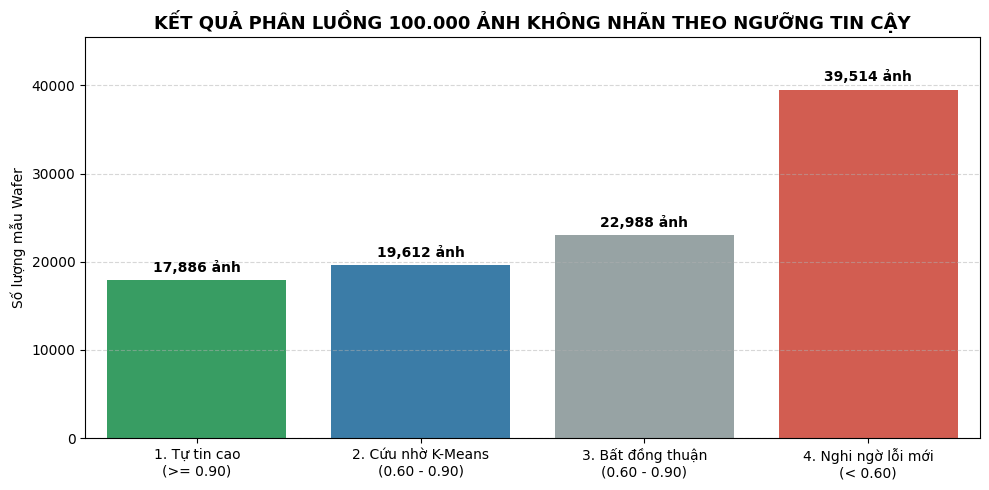

In [32]:
if 'cluster_to_dominant_label' not in globals():
    crosstab_km = pd.crosstab(df_subset['Cluster_Label'], df_subset['failureType'], normalize='index')
    cluster_to_dominant_label = crosstab_km.idxmax(axis=1).to_dict()

print("1. Chuẩn bị định dạng 100k ảnh không nhãn cho CNN...")
X_unlabeled_cnn = np.stack(df_final_large['waferMap_resized'].values).astype('float32') / 2.0
X_unlabeled_cnn = np.expand_dims(X_unlabeled_cnn, axis=-1)

print("2. Mô hình CNN v1 đang dự đoán trên 100k ảnh...")
pseudo_probs = model.predict(X_unlabeled_cnn, batch_size=256, verbose=1)
max_probs = np.max(pseudo_probs, axis=1)
pseudo_labels_num = np.argmax(pseudo_probs, axis=1)

# Lưu tên nhãn chữ ('Normal', 'Scratch',...) và độ tự tin vào DataFrame
df_final_large['Pseudo_Label'] = le.inverse_transform(pseudo_labels_num)
df_final_large['Confidence'] = max_probs
df_final_large['KMeans_Dominant_Label'] = df_final_large['Cluster_Label'].map(cluster_to_dominant_label)

# 3. ĐỊNH NGHĨA 3 VÙNG THRESHOLD BAO QUÁT TOÀN BỘ 100.000 ẢNH
HIGH_CONF_THRESH = 0.90
LOW_CONF_THRESH = 0.60

# Nhánh 1: >= 0.90 (Tin tưởng tuyệt đối)
cond_high = df_final_large['Confidence'] >= HIGH_CONF_THRESH

# Nhánh 2: 0.60 <= Confidence < 0.90 (Vùng trung gian - Đối chiếu chéo với K-Means)
cond_mid = (df_final_large['Confidence'] >= LOW_CONF_THRESH) & (df_final_large['Confidence'] < HIGH_CONF_THRESH)
cond_mid_rescued = cond_mid & (df_final_large['Pseudo_Label'] == df_final_large['KMeans_Dominant_Label'])
cond_mid_conflict = cond_mid & (df_final_large['Pseudo_Label'] != df_final_large['KMeans_Dominant_Label'])

# Nhánh 3: < 0.60 (Mô hình bối rối -> Nghi ngờ lỗi mới)
cond_low = df_final_large['Confidence'] < LOW_CONF_THRESH

# Lấy danh sách Index của từng nhóm
high_conf_idx = np.where(cond_high)[0]
rescued_mid_idx = np.where(cond_mid_rescued)[0]
conflict_mid_idx = np.where(cond_mid_conflict)[0]
low_conf_idx = np.where(cond_low)[0]

# Hợp nhất các mẫu Pseudo-Label đạt chuẩn (Nhánh 1 + Nhánh 2 đồng thuận)
accepted_pseudo_idx = np.concatenate([high_conf_idx, rescued_mid_idx])

print("\n=== BÁO CÁO PHÂN LUỒNG TOÀN DIỆN 100.000 ẢNH (PSEUDO-LABELING) ===")
print(f"1. Happy Case 1 (>= 0.90 - Tự tin cao)              : {len(high_conf_idx):,} ảnh -> Gán nhãn giả")
print(f"2. Happy Case 2 (0.60 -> <0.90 & Khớp cụm K-Means)  : {len(rescued_mid_idx):,} ảnh -> Cứu thêm làm nhãn giả")
print(f"   -> TỔNG MẪU PSEUDO-LABEL ĐƯỢC CHẤP NHẬN          : {len(accepted_pseudo_idx):,} ảnh")
print(f"3. Vùng nhiễu (0.60 -> <0.90 nhưng lệch K-Means)    : {len(conflict_mid_idx):,} ảnh -> Tạm gác lại tránh bẩn dữ liệu")
print(f"4. Happy Case 3 (< 0.60 - Nghi ngờ lỗi hình thái lạ): {len(low_conf_idx):,} ảnh -> Đẩy xuống Isolation Forest & CURE")
print(f"-> TỔNG ĐỐI SOÁT                                    : {len(high_conf_idx) + len(rescued_mid_idx) + len(conflict_mid_idx) + len(low_conf_idx):,} / {len(df_final_large):,} ảnh")

# 4. VẼ BIỂU ĐỒ TRỰC QUAN HÓA KẾT QUẢ PHÂN LUỒNG 100K ẢNH
flow_df = pd.DataFrame({
    'Nhánh xử lý': [
        '1. Tự tin cao\n(>= 0.90)',
        '2. Cứu nhờ K-Means\n(0.60 - 0.90)',
        '3. Bất đồng thuận\n(0.60 - 0.90)',
        '4. Nghi ngờ lỗi mới\n(< 0.60)'
    ],
    'Số lượng ảnh': [len(high_conf_idx), len(rescued_mid_idx), len(conflict_mid_idx), len(low_conf_idx)]
})

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=flow_df, x='Nhánh xử lý', y='Số lượng ảnh', 
    hue='Nhánh xử lý', palette=['#27ae60', '#2980b9', '#95a5a6', '#e74c3c'], legend=False
)
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f} ảnh', padding=4, fontweight='bold')
ax.margins(y=0.15)
plt.title('KẾT QUẢ PHÂN LUỒNG 100.000 ẢNH KHÔNG NHÃN THEO NGƯỠNG TIN CẬY', fontsize=13, fontweight='bold')
plt.xlabel('')
plt.ylabel('Số lượng mẫu Wafer')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# **GIAI ĐOẠN 5: PHÁT HIỆN BẤT THƯỜNG (ISOLATION FOREST) & GOM CỤM LỖI MỚI (CURE)**

Đang chạy Isolation Forest trên nhóm nghi ngờ (< 0.60) để lọc Wafer dị thường...
Phát hiện 3,952 Wafer bất thường (Outliers) từ 39,514 mẫu nghi ngờ!


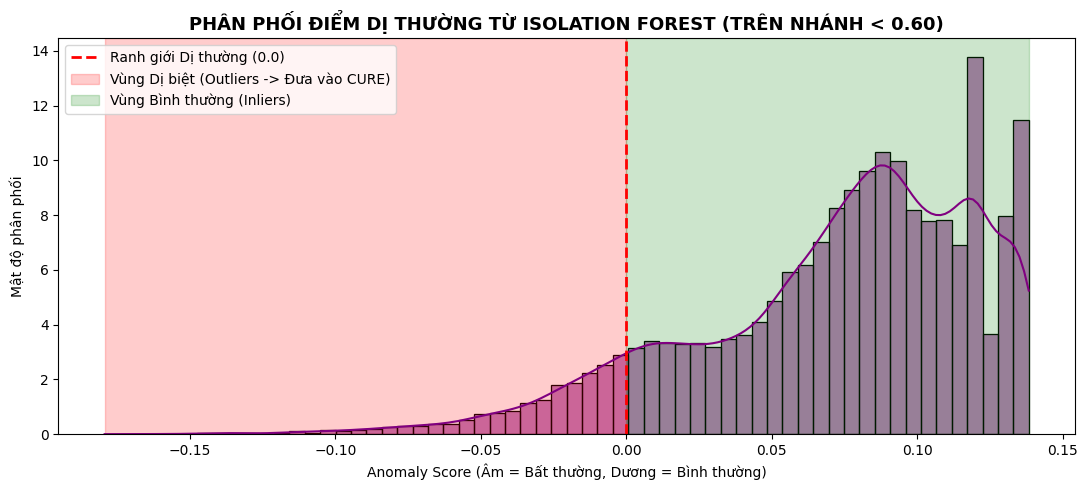

In [33]:
print("Đang chạy Isolation Forest trên nhóm nghi ngờ (< 0.60) để lọc Wafer dị thường...")

if len(low_conf_idx) < 10:
    raise ValueError("Số lượng mẫu < 0.60 quá ít để chạy Isolation Forest. Hãy cân nhắc nâng LOW_CONF_THRESH lên 0.70.")

features_low_conf = features_100k[low_conf_idx]

iso_forest = IsolationForest(n_estimators=200, contamination=0.1, random_state=42)
anomaly_preds = iso_forest.fit_predict(features_low_conf)
anomaly_scores = iso_forest.decision_function(features_low_conf)

# Lấy các điểm bất thường (-1) và ánh xạ ngược về index gốc của bảng 100k
outlier_local_idx = np.where(anomaly_preds == -1)[0]
outlier_global_idx = low_conf_idx[outlier_local_idx]

print(f"Phát hiện {len(outlier_global_idx):,} Wafer bất thường (Outliers) từ {len(low_conf_idx):,} mẫu nghi ngờ!")

# Vẽ biểu đồ Phân phối Điểm dị thường
plt.figure(figsize=(11, 5))
ax = sns.histplot(anomaly_scores, bins=60, kde=True, color='purple', stat='density')
plt.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Ranh giới Dị thường (0.0)')
ax.axvspan(anomaly_scores.min(), 0, alpha=0.2, color='red', label='Vùng Dị biệt (Outliers -> Đưa vào CURE)')
ax.axvspan(0, anomaly_scores.max(), alpha=0.2, color='green', label='Vùng Bình thường (Inliers)')
plt.title('PHÂN PHỐI ĐIỂM DỊ THƯỜNG TỪ ISOLATION FOREST (TRÊN NHÁNH < 0.60)', fontsize=13, fontweight='bold')
plt.xlabel('Anomaly Score (Âm = Bất thường, Dương = Bình thường)')
plt.ylabel('Mật độ phân phối')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

**Biểu đồ Phân phối Điểm dị thường (Isolation Forest Anomaly Score)**

Đang vẽ biểu đồ Phân phối Điểm dị thường (Anomaly Scores)...


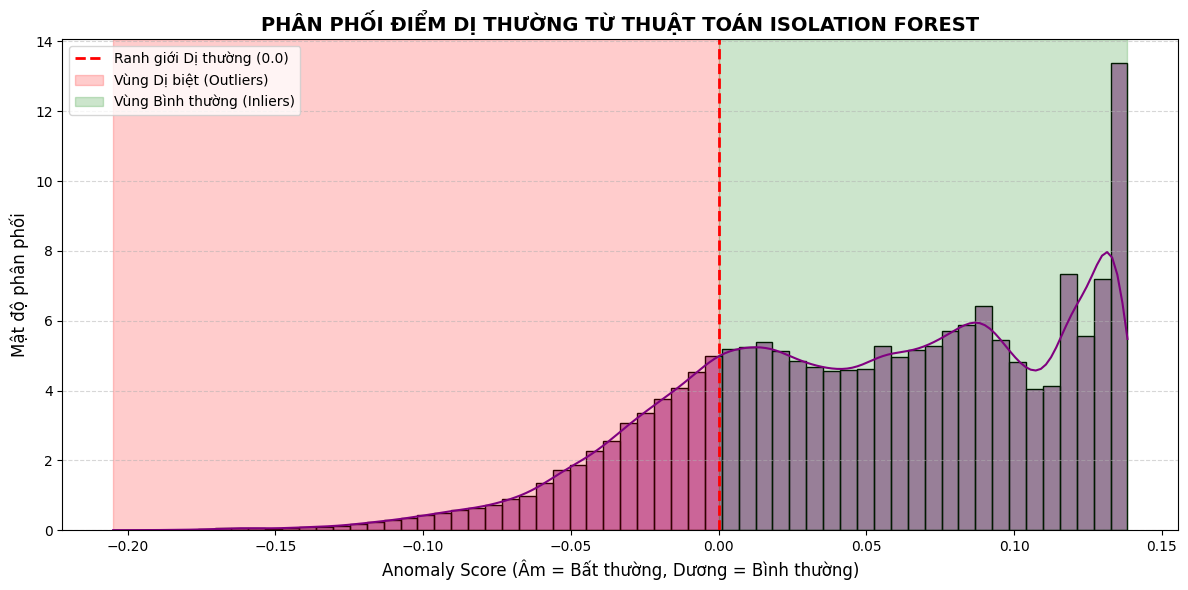

In [34]:
print("Đang vẽ biểu đồ Phân phối Điểm dị thường (Anomaly Scores)...")

# Thay features_pca bằng features_100k (biến chứa dữ liệu 128 chiều của bạn)
# Nếu mô hình Isolation Forest của bạn mang tên khác (như 'clf' hay 'model_if'), 
# bạn cũng sửa chữ 'iso_forest' cho khớp nhé.
anomaly_scores = iso_forest.decision_function(features_100k)

plt.figure(figsize=(12, 6))
ax = sns.histplot(anomaly_scores, bins=60, kde=True, color='purple', stat='density')

# Vẽ ranh giới phân tách (Điểm 0)
plt.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Ranh giới Dị thường (0.0)')

# Highlight vùng chứa lỗi mới và vùng bình thường
ax.axvspan(anomaly_scores.min(), 0, alpha=0.2, color='red', label='Vùng Dị biệt (Outliers)')
ax.axvspan(0, anomaly_scores.max(), alpha=0.2, color='green', label='Vùng Bình thường (Inliers)')

plt.title('PHÂN PHỐI ĐIỂM DỊ THƯỜNG TỪ THUẬT TOÁN ISOLATION FOREST', fontsize=14, fontweight='bold')
plt.xlabel('Anomaly Score (Âm = Bất thường, Dương = Bình thường)', fontsize=12)
plt.ylabel('Mật độ phân phối', fontsize=12)
plt.legend(loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Phân cụm hình thái lỗi mới bằng CURE & Đánh giá định lượng ngay lập tức**

1. Đang áp dụng thuật toán CURE lên các Wafer bất thường...
CURE đã phân tách thành công 5 cụm lỗi bất thường mới!
-> Silhouette Score     : 0.3667 (Càng gần 1 càng tách biệt rõ)
-> Davies-Bouldin Index : 0.4682 (Càng gần 0 càng liên kết chặt)


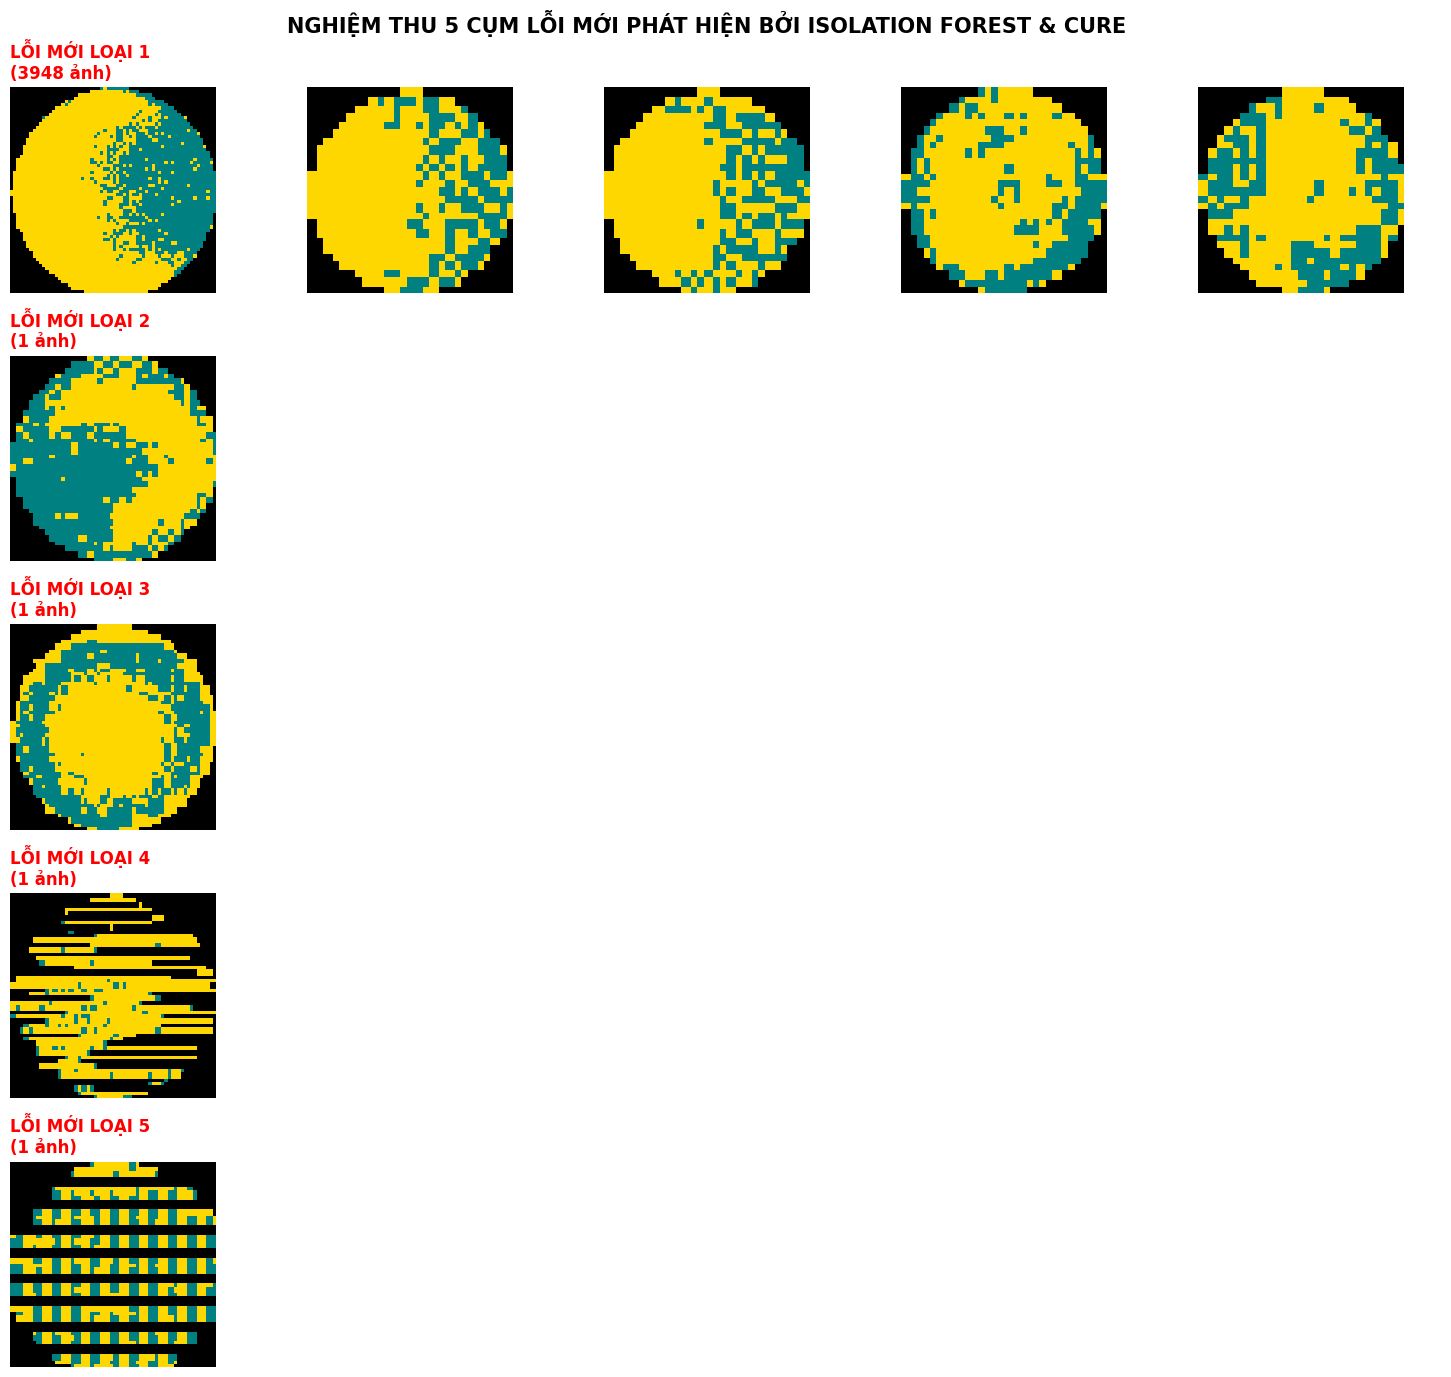

In [35]:
print("1. Đang áp dụng thuật toán CURE lên các Wafer bất thường...")
cure_data = features_100k[outlier_global_idx].tolist()

cure_instance = cure(cure_data, number_cluster=5, number_represent_points=5, compression=0.5)
cure_instance.process()
cure_clusters = cure_instance.get_clusters()
print(f"CURE đã phân tách thành công {len(cure_clusters)} cụm lỗi bất thường mới!")

# 2. ĐÁNH GIÁ ĐỊNH LƯỢNG (SILHOUETTE & DAVIES-BOULDIN) NGAY SAU KHI PHÂN CỤM
cure_labels = np.full(len(cure_data), -1)
for cluster_id, cluster_indices in enumerate(cure_clusters):
    for idx in cluster_indices:
        cure_labels[idx] = cluster_id

valid_idx = cure_labels != -1
if len(set(cure_labels[valid_idx])) > 1:
    sil_score = silhouette_score(np.array(cure_data)[valid_idx], cure_labels[valid_idx])
    db_score = davies_bouldin_score(np.array(cure_data)[valid_idx], cure_labels[valid_idx])
    print(f"-> Silhouette Score     : {sil_score:.4f} (Càng gần 1 càng tách biệt rõ)")
    print(f"-> Davies-Bouldin Index : {db_score:.4f} (Càng gần 0 càng liên kết chặt)")

# 3. TRỰC QUAN HÓA HÌNH ẢNH 5 CỤM CURE ĐỂ NGHIỆM THU BẰNG MẮT THƯỜNG
fig, axes = plt.subplots(len(cure_clusters), 5, figsize=(15, 2.8 * len(cure_clusters)))
fig.suptitle('NGHIỆM THU 5 CỤM LỖI MỚI PHÁT HIỆN BỞI ISOLATION FOREST & CURE', fontsize=15, fontweight='bold')

for i, cluster_indices in enumerate(cure_clusters):
    sample_size = min(5, len(cluster_indices))
    for j in range(5):
        ax = axes[i, j] if len(cure_clusters) > 1 else axes[j]
        if j < sample_size:
            real_idx = outlier_global_idx[cluster_indices[j]]
            img = df_final_large.iloc[real_idx]['waferMap_resized']
            ax.imshow(img, cmap=cmap, vmin=0, vmax=2)
            if j == 0:
                ax.set_title(f"LỖI MỚI LOẠI {i+1}\n({len(cluster_indices)} ảnh)", loc='left', fontweight='bold', color='red')
        ax.axis('off')

plt.tight_layout()
plt.show()

# **GIAI ĐOẠN 6: HỢP NHẤT DỮ LIỆU VERSION 2.0 (10 CLASSES) & HUẤN LUYỆN LẠI CNN**

In [36]:
cols_to_train = ['waferMap_resized', 'failureType']

# Nguồn 1: Tập Pseudo-Label độ tin cậy cao (>= 0.90 + 0.60..0.90 khớp K-Means)
df_pseudo_accepted = df_final_large.iloc[accepted_pseudo_idx].copy()
df_pseudo_accepted['failureType'] = df_pseudo_accepted['Pseudo_Label']

# Nguồn 2: Nhãn mới thứ 10 từ CURE (Cụm 4 và Cụm 5, có kiểm tra an toàn số cụm)
if len(cure_clusters) >= 5:
    new_defect_local_idx = cure_clusters[3] + cure_clusters[4]
else:
    new_defect_local_idx = max(cure_clusters, key=len)

new_defect_global_idx = outlier_global_idx[new_defect_local_idx]
df_new_label = df_final_large.iloc[new_defect_global_idx].copy()
df_new_label['failureType'] = 'Horizontal_Stripes'

# Hợp nhất cả 3 nguồn thành Tập Train Version 2.0
df_train_version2 = pd.concat([
    df_subset[cols_to_train],          # Tập gốc (9 class)
    df_pseudo_accepted[cols_to_train], # Tập Pseudo-Label làm giàu cho 9 class cũ
    df_new_label[cols_to_train]        # Class thứ 10 mới khám phá ('Horizontal_Stripes')
], ignore_index=True)

print("=== THỐNG KÊ TẬP DỮ LIỆU VERSION 2.0 (10 CLASSES) ===")
print(f"- Nguồn 1 (Tập có nhãn gốc)         : {len(df_subset):,} ảnh")
print(f"- Nguồn 2 (Pseudo-Label chấp nhận)  : {len(df_pseudo_accepted):,} ảnh")
print(f"- Nguồn 3 (Nhãn thứ 10 từ CURE)     : {len(df_new_label):,} ảnh")
print(f"=> TỔNG QUY MÔ TẬP TRAIN VERSION 2.0: {len(df_train_version2):,} ảnh\n")
display(df_train_version2['failureType'].value_counts().to_frame(name='Số lượng mẫu'))

=== THỐNG KÊ TẬP DỮ LIỆU VERSION 2.0 (10 CLASSES) ===
- Nguồn 1 (Tập có nhãn gốc)         : 51,038 ảnh
- Nguồn 2 (Pseudo-Label chấp nhận)  : 37,498 ảnh
- Nguồn 3 (Nhãn thứ 10 từ CURE)     : 2 ảnh
=> TỔNG QUY MÔ TẬP TRAIN VERSION 2.0: 88,538 ảnh



,Số lượng mẫu
failureType,
Normal,40723
Loc,12673
Edge-Loc,12072
Edge-Ring,11021
Center,7806
Random,1713
Scratch,1449
Donut,617
Near-full,462


**Phân tích đặc trưng không gian của 10 Classes (KDE, Spatial Heatmap, t-SNE)**

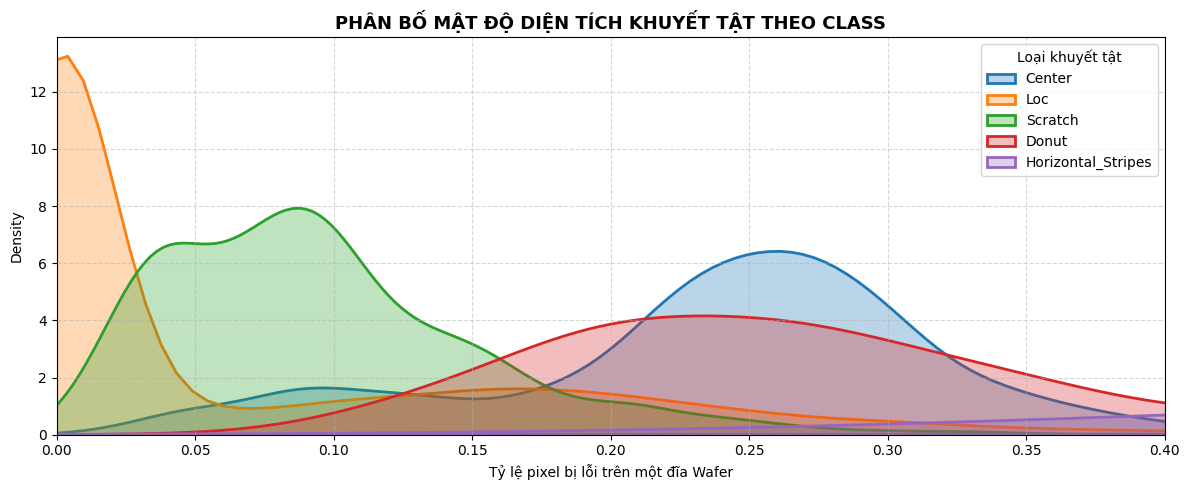

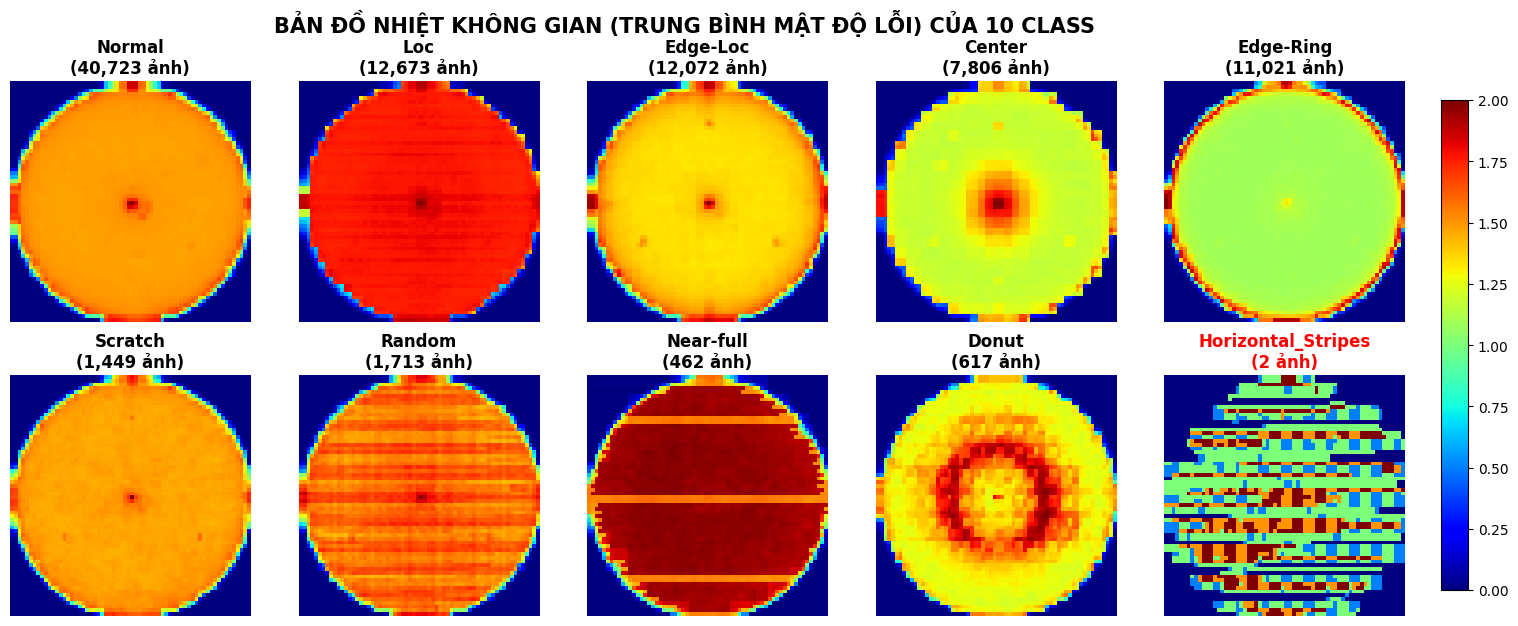

Đang chạy t-SNE trên 3.000 mẫu đại diện của 10 Class...


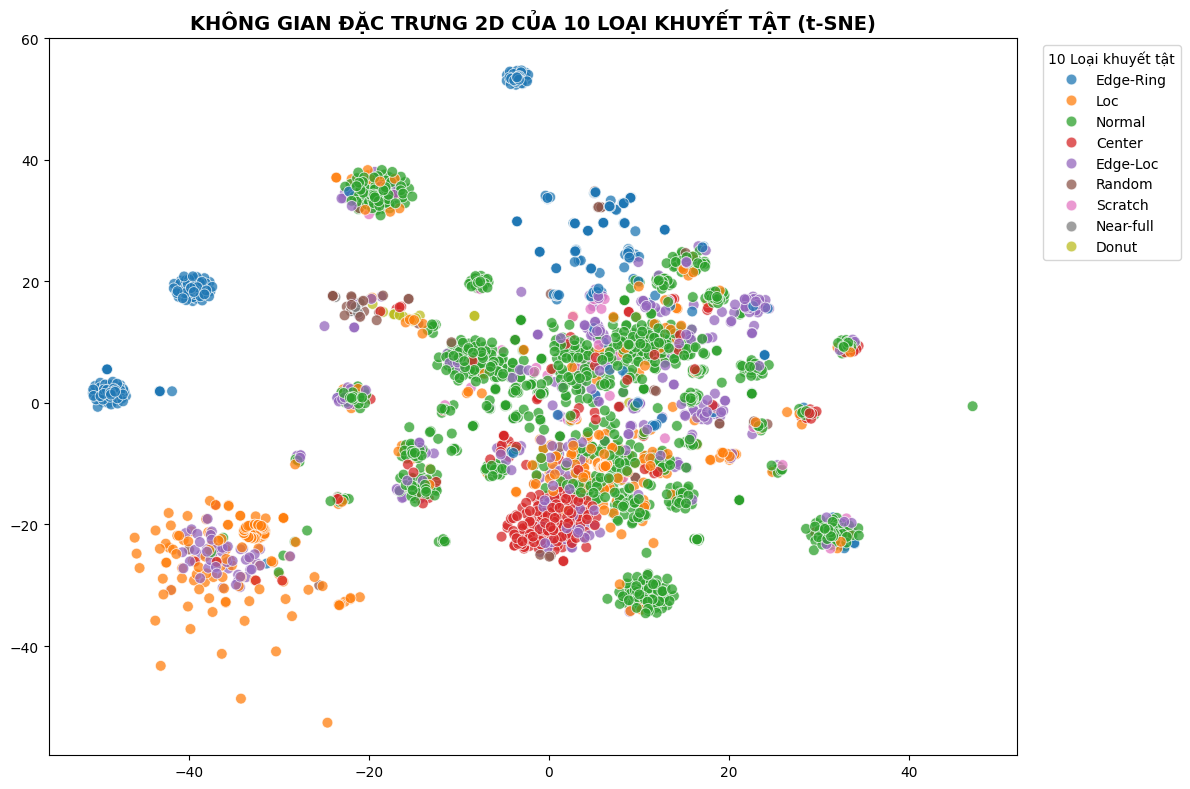

In [37]:
# 1. BIỂU ĐỒ MẬT ĐỘ DIỆN TÍCH KHUYẾT TẬT (KDE PLOT)
def calculate_defect_ratio(matrix):
    total_valid = np.sum(matrix > 0)
    defect_px = np.sum(matrix == 2)
    return defect_px / total_valid if total_valid > 0 else 0

df_train_version2['defect_ratio'] = df_train_version2['waferMap_resized'].apply(calculate_defect_ratio)

plt.figure(figsize=(12, 5))
for label in ['Center', 'Loc', 'Scratch', 'Donut', 'Horizontal_Stripes']:
    subset = df_train_version2[df_train_version2['failureType'] == label]
    sns.kdeplot(subset['defect_ratio'], label=label, fill=True, linewidth=2, alpha=0.3)
plt.title('PHÂN BỐ MẬT ĐỘ DIỆN TÍCH KHUYẾT TẬT THEO CLASS', fontsize=13, fontweight='bold')
plt.xlabel('Tỷ lệ pixel bị lỗi trên một đĩa Wafer')
plt.xlim(0, 0.4)
plt.legend(title='Loại khuyết tật')
plt.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 2. BẢN ĐỒ NHIỆT KHÔNG GIAN (SPATIAL AVERAGE HEATMAP) CHO 10 CLASS
unique_labels = df_train_version2['failureType'].unique()
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
fig.suptitle('BẢN ĐỒ NHIỆT KHÔNG GIAN (TRUNG BÌNH MẬT ĐỘ LỖI) CỦA 10 CLASS', fontsize=15, fontweight='bold')

for i, label in enumerate(unique_labels):
    class_matrices = df_train_version2[df_train_version2['failureType'] == label]['waferMap_resized'].values
    mean_matrix = np.mean(np.stack(class_matrices), axis=0)
    ax = axes.flat[i]
    im = ax.imshow(mean_matrix, cmap='jet')
    ax.set_title(f"{label}\n({len(class_matrices):,} ảnh)", fontweight='bold',
                 color='red' if label == 'Horizontal_Stripes' else 'black')
    ax.axis('off')

cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
fig.colorbar(im, cax=cbar_ax)
plt.show()

# 3. BIỂU ĐỒ t-SNE 2D TÁCH CỤM 10 CLASS
print("Đang chạy t-SNE trên 3.000 mẫu đại diện của 10 Class...")
sample_viz = df_train_version2.sample(n=min(3000, len(df_train_version2)), random_state=42)
X_viz_flat = np.array([wm.flatten() for wm in sample_viz['waferMap_resized'].values])
y_viz = sample_viz['failureType'].values

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
features_2d = tsne.fit_transform(X_viz_flat)

plt.figure(figsize=(12, 8))
sns.scatterplot(x=features_2d[:, 0], y=features_2d[:, 1], hue=y_viz, palette='tab10', s=60, alpha=0.75)
plt.title('KHÔNG GIAN ĐẶC TRƯNG 2D CỦA 10 LOẠI KHUYẾT TẬT (t-SNE)', fontsize=14, fontweight='bold')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title="10 Loại khuyết tật")
plt.tight_layout()
plt.show()

**Huấn luyện & Kiểm chứng CNN Version 2.0 (10 Classes)**

In [41]:
print("=== HUẤN LUYỆN NHANH CNN VERSION 2.0 (ĐẦY ĐỦ 10 CLASSES) ===")

# 1. Cân bằng dữ liệu thông minh:
# - Nhãn nào quá nhiều (> 4.000 mẫu như Normal) -> Rút gọn về 4.000 mẫu cho nhẹ máy
# - Nhãn nào quá ít (< 300 mẫu như Horizontal_Stripes mới tìm ra) -> Nhân bản (Oversample) lên 300 mẫu để đủ chia Train/Test
balanced_groups = []
for label_name, group in df_train_version2.groupby('failureType'):
    if len(group) > 4000:
        balanced_groups.append(group.sample(n=4000, random_state=42))
    elif len(group) < 300:
        balanced_groups.append(group.sample(n=300, replace=True, random_state=42))
    else:
        balanced_groups.append(group)

df_v2_balanced = pd.concat(balanced_groups, ignore_index=True)
print(f"Đã tối ưu tập dữ liệu: {len(df_v2_balanced):,} ảnh. Số lượng mẫu mỗi nhãn:")
print(df_v2_balanced['failureType'].value_counts())

# 2. Mã hóa 10 nhãn và chuẩn bị ma trận
le_v2 = LabelEncoder()
y_v2 = le_v2.fit_transform(df_v2_balanced['failureType'])
num_classes_v2 = len(le_v2.classes_)

X_v2 = np.stack(df_v2_balanced['waferMap_resized'].values).astype('float32') / 2.0
X_v2 = np.expand_dims(X_v2, axis=-1)

X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_split(
    X_v2, y_v2, test_size=0.2, random_state=42, stratify=y_v2
)

# 3. Tính Class Weights làm mượt cho 10 nhãn
raw_w_v2 = class_weight.compute_class_weight('balanced', classes=np.unique(y_train_v2), y=y_train_v2)
class_weight_dict_v2 = dict(enumerate(np.clip(np.sqrt(raw_w_v2), 0.5, 5.0)))

# 4. Kế thừa trọng số từ model v1 (Clone sang kiến trúc 10 classes và mở khóa để học nhãn thứ 10)
model_v2 = build_cnn_model(num_classes=num_classes_v2)

# Copy trọng số của toàn bộ các tầng (trừ tầng Dense cuối cùng) từ model v1 sang model_v2
for l_v2, l_v1 in zip(model_v2.layers[:-1], model.layers[:-1]):
    l_v2.set_weights(l_v1.get_weights())

model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4), # Learning rate vừa phải để tinh chỉnh mượt
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 5. Huấn luyện 6 epochs với batch_size=256 (chỉ mất khoảng 30-40 giây)
print("\nBắt đầu Fine-tune toàn mạng cho 10 Classes...")
history_v2 = model_v2.fit(
    X_train_v2, y_train_v2,
    epochs=6,
    batch_size=256,
    validation_data=(X_test_v2, y_test_v2),
    class_weight=class_weight_dict_v2
)

# 6. Đánh giá kết quả & Kẻ bảng (Thêm tham số labels=range(num_classes_v2) để KHÔNG bị ValueError)
y_pred_v2 = np.argmax(model_v2.predict(X_test_v2, batch_size=256, verbose=0), axis=1)

report_v2_dict = classification_report(
    y_test_v2, y_pred_v2,
    labels=range(num_classes_v2),      # Khóa cứng đủ 10 index (0 -> 9) chống lỗi ValueError
    target_names=le_v2.classes_,
    output_dict=True,
    zero_division=0
)

df_report_v2 = pd.DataFrame(report_v2_dict).transpose().drop(index='accuracy', errors='ignore')
df_report_v2.columns = ['Precision', 'Recall', 'F1-Score', 'Support (Số mẫu)']

print(f"\n=== BÁO CÁO PHÂN LOẠI CUỐI CÙNG (CNN VERSION 2.0 - {num_classes_v2} CLASSES) ===")
display(
    df_report_v2.style
    .format({'Precision': '{:.4f}', 'Recall': '{:.4f}', 'F1-Score': '{:.4f}', 'Support (Số mẫu)': '{:,.0f}'})
    .background_gradient(cmap='YlGn', subset=['Precision', 'Recall', 'F1-Score'], vmin=0.5, vmax=1.0)
)

=== HUẤN LUYỆN NHANH CNN VERSION 2.0 (ĐẦY ĐỦ 10 CLASSES) ===
Đã tối ưu tập dữ liệu: 24,541 ảnh. Số lượng mẫu mỗi nhãn:
failureType
Center                4000
Edge-Loc              4000
Loc                   4000
Edge-Ring             4000
Normal                4000
Random                1713
Scratch               1449
Donut                  617
Near-full              462
Horizontal_Stripes     300
Name: count, dtype: int64

Bắt đầu Fine-tune toàn mạng cho 10 Classes...
Epoch 1/6
77/77 ━━━━━━━━━━━━━━━━━━━━ 69s 875ms/step - accuracy: 0.4345 - loss: 1.6278 - val_accuracy: 0.7938 - val_loss: 0.8943
Epoch 2/6
77/77 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.7029 - loss: 0.8535 - val_accuracy: 0.8266 - val_loss: 0.5809
Epoch 3/6
77/77 ━━━━━━━━━━━━━━━━━━━━ 67s 869ms/step - accuracy: 0.7550 - loss: 0.6653 - val_accuracy: 0.8450 - val_loss: 0.4811
Epoch 4/6
77/77 ━━━━━━━━━━━━━━━━━━━━ 66s 863ms/step - accuracy: 0.7953 - loss: 0.5540 - val_accuracy: 0.8645 - val_loss: 0.4275
Epoch 5/6
77/77 ━

,Precision,Recall,F1-Score,Support (Số mẫu)
Center,0.9569,0.9425,0.9496,800
Donut,0.8108,0.9677,0.8824,124
Edge-Loc,0.8417,0.8638,0.8526,800
Edge-Ring,0.9636,0.9587,0.9612,800
Horizontal_Stripes,1.0000,1.0000,1.0000,60
Loc,0.9759,0.7100,0.8220,800
Near-full,0.9681,0.9891,0.9785,92
Normal,0.7214,0.9550,0.8219,800
Random,0.9459,0.9679,0.9568,343
Scratch,0.7667,0.5552,0.6440,290


**Biểu đồ sau Train lại V2.0 với 10 nhãn**

Đang xuất bộ biểu đồ đánh giá toàn diện cho CNN Version 2.0 (10 Classes)...


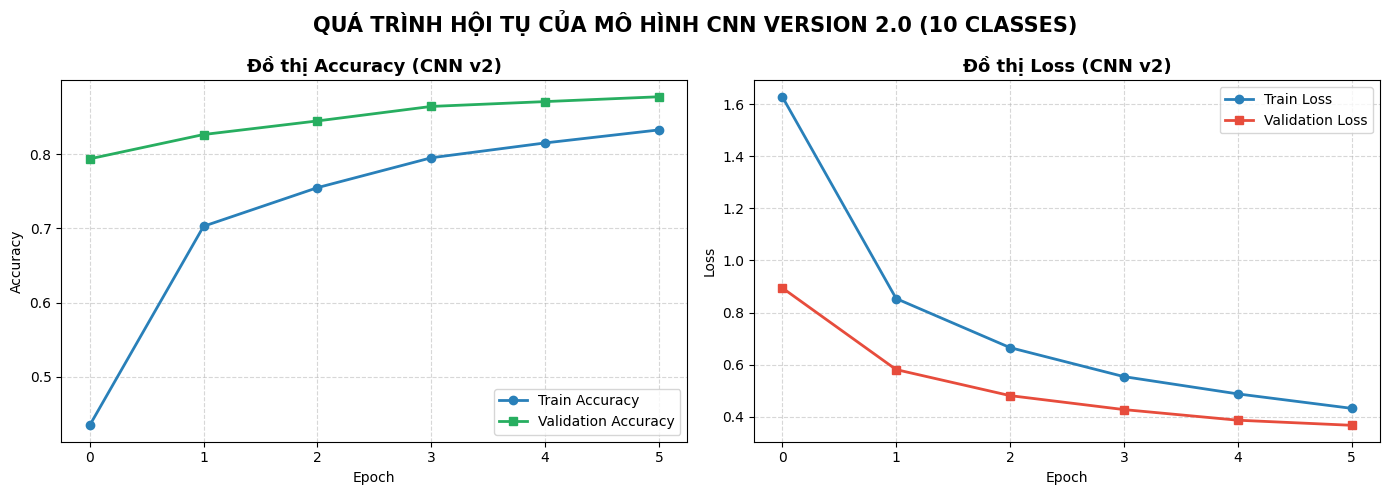

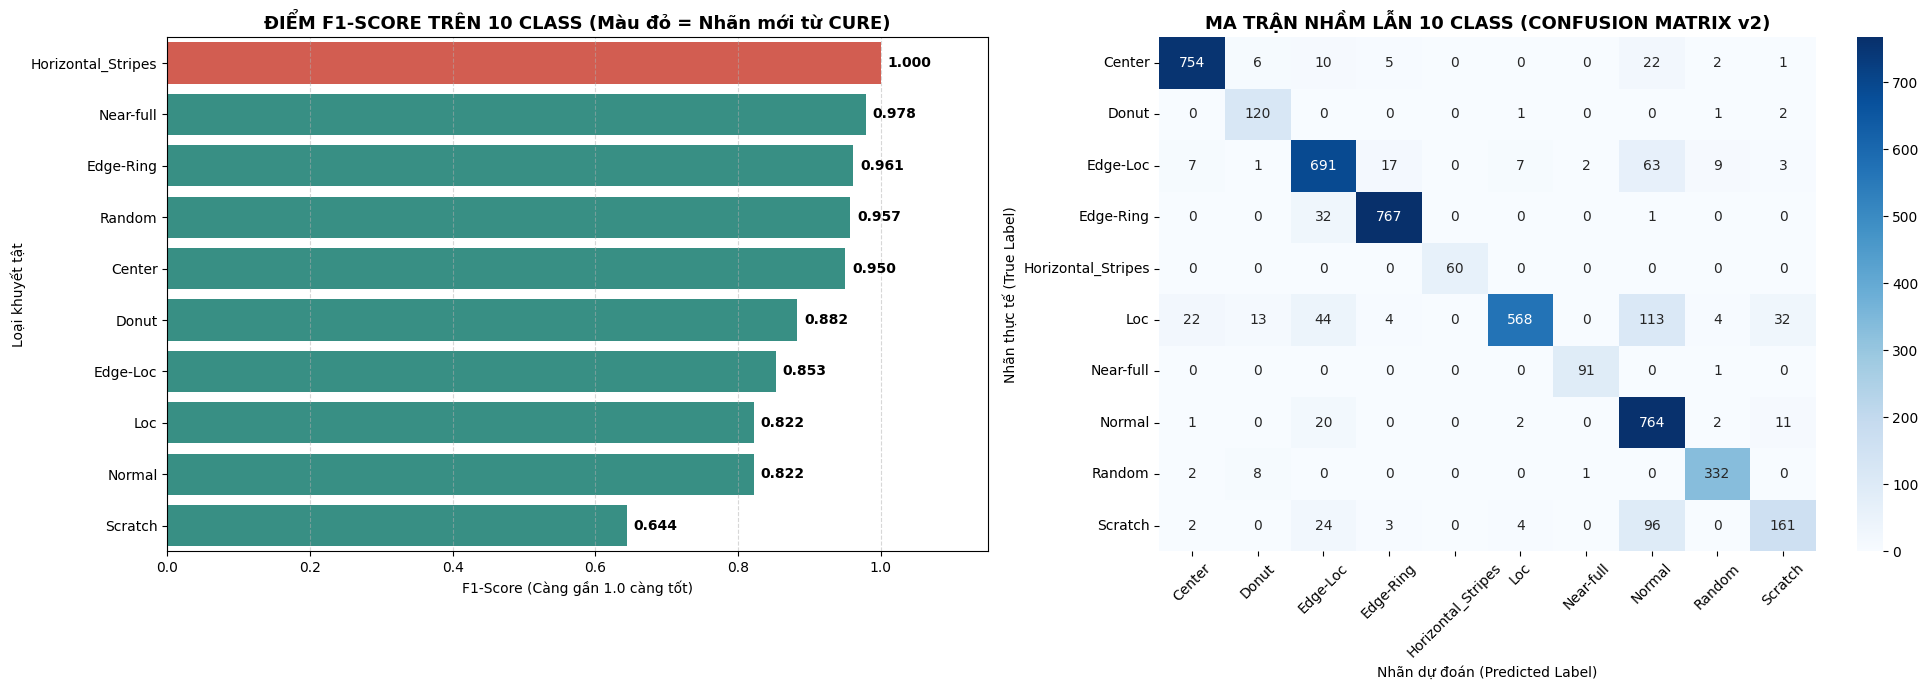

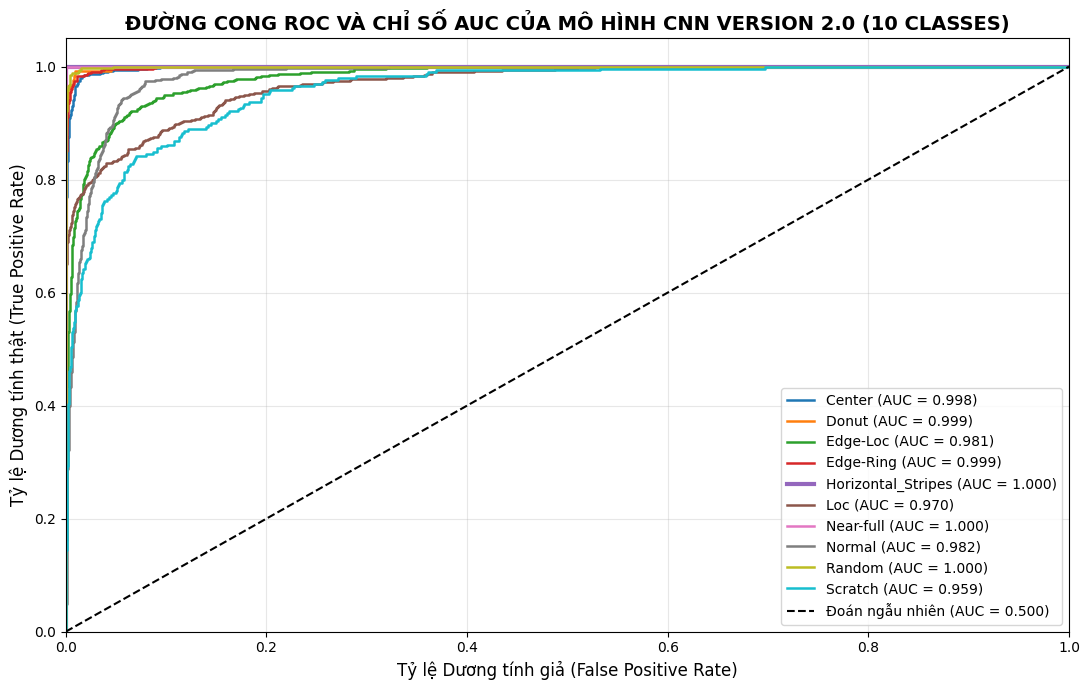

In [42]:
print("Đang xuất bộ biểu đồ đánh giá toàn diện cho CNN Version 2.0 (10 Classes)...")

# Dự đoán xác suất 1 lần duy nhất trên tập Test v2 để dùng chung cho mọi biểu đồ
y_pred_probs_v2 = model_v2.predict(X_test_v2, batch_size=256, verbose=0)
y_pred_v2 = np.argmax(y_pred_probs_v2, axis=1)
num_classes_v2 = len(le_v2.classes_)

# 1. ĐỒ THỊ ACCURACY & LOSS QUA CÁC EPOCH (CNN VERSION 2.0)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('QUÁ TRÌNH HỘI TỤ CỦA MÔ HÌNH CNN VERSION 2.0 (10 CLASSES)', fontsize=15, fontweight='bold')

ax1.plot(history_v2.history['accuracy'], marker='o', linewidth=2, color='#2980b9', label='Train Accuracy')
ax1.plot(history_v2.history['val_accuracy'], marker='s', linewidth=2, color='#27ae60', label='Validation Accuracy')
ax1.set_title('Đồ thị Accuracy (CNN v2)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='lower right')

ax2.plot(history_v2.history['loss'], marker='o', linewidth=2, color='#2980b9', label='Train Loss')
ax2.plot(history_v2.history['val_loss'], marker='s', linewidth=2, color='#e74c3c', label='Validation Loss')
ax2.set_title('Đồ thị Loss (CNN v2)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

# 2. BIỂU ĐỒ F1-SCORE (HIGHLIGHT NHÃN MỚI) & MA TRẬN NHẦM LẪN 10x10
report_v2_dict = classification_report(
    y_test_v2, y_pred_v2,
    labels=range(num_classes_v2),
    target_names=le_v2.classes_,
    output_dict=True,
    zero_division=0
)

f1_scores_v2 = {k: v['f1-score'] for k, v in report_v2_dict.items() if k in le_v2.classes_}
df_f1_v2 = pd.DataFrame(list(f1_scores_v2.items()), columns=['Khuyết tật', 'F1-Score']).sort_values(by='F1-Score', ascending=False)

# Tô màu đỏ cam cho nhãn mới 'Horizontal_Stripes', các nhãn cũ màu xanh cổ vịt
bar_colors = ['#e74c3c' if x == 'Horizontal_Stripes' else '#2a9d8f' for x in df_f1_v2['Khuyết tật']]

fig, (ax_f1, ax_cm) = plt.subplots(1, 2, figsize=(20, 7))

# --- Biểu đồ 2A: F1-Score từng Class ---
sns.barplot(x='F1-Score', y='Khuyết tật', data=df_f1_v2, hue='Khuyết tật', palette=bar_colors, legend=False, ax=ax_f1)
for p in ax_f1.patches:
    ax_f1.annotate(f"{p.get_width():.3f}", 
                   (p.get_width(), p.get_y() + p.get_height() / 2.),
                   ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontweight='bold')
ax_f1.set_xlim(0, 1.15)
ax_f1.set_title('ĐIỂM F1-SCORE TRÊN 10 CLASS (Màu đỏ = Nhãn mới từ CURE)', fontsize=13, fontweight='bold')
ax_f1.set_xlabel('F1-Score (Càng gần 1.0 càng tốt)')
ax_f1.set_ylabel('Loại khuyết tật')
ax_f1.grid(axis='x', linestyle='--', alpha=0.5)

# --- Biểu đồ 2B: Confusion Matrix 10x10 ---
cm_v2 = confusion_matrix(y_test_v2, y_pred_v2, labels=range(num_classes_v2))
sns.heatmap(cm_v2, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le_v2.classes_, yticklabels=le_v2.classes_, ax=ax_cm)
ax_cm.set_title('MA TRẬN NHẦM LẪN 10 CLASS (CONFUSION MATRIX v2)', fontsize=13, fontweight='bold')
ax_cm.set_ylabel('Nhãn thực tế (True Label)')
ax_cm.set_xlabel('Nhãn dự đoán (Predicted Label)')
ax_cm.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# 3. ĐƯỜNG CONG ROC ĐA LỚP (MULTICLASS ROC & AUC CHO 10 CLASSES)
y_test_bin_v2 = label_binarize(y_test_v2, classes=range(num_classes_v2))

plt.figure(figsize=(11, 7))
colors_roc = plt.cm.tab10(np.linspace(0, 1, num_classes_v2))

for i, color in zip(range(num_classes_v2), colors_roc):
    cls_name = le_v2.classes_[i]
    # Kiểm tra nếu class có mặt trong tập Test để tránh lỗi chia cho 0 khi tính ROC
    if np.sum(y_test_bin_v2[:, i]) > 0:
        fpr, tpr, _ = roc_curve(y_test_bin_v2[:, i], y_pred_probs_v2[:, i])
        roc_auc = auc(fpr, tpr)
        # Vẽ nét dày hơn cho nhãn mới Horizontal_Stripes
        lw = 3.0 if cls_name == 'Horizontal_Stripes' else 1.8
        plt.plot(fpr, tpr, color=color, lw=lw, label=f'{cls_name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Đoán ngẫu nhiên (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tỷ lệ Dương tính giả (False Positive Rate)', fontsize=12)
plt.ylabel('Tỷ lệ Dương tính thật (True Positive Rate)', fontsize=12)
plt.title('ĐƯỜNG CONG ROC VÀ CHỈ SỐ AUC CỦA MÔ HÌNH CNN VERSION 2.0 (10 CLASSES)', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Xuất model**

In [48]:
# Tắt triệt để các dòng WARNING:absl của TensorFlow/Keras
absl.logging.set_verbosity(absl.logging.ERROR)

# 1. Xuất mạng nơ-ron CNN chuẩn .keras (Không bao giờ báo Warning)
model_v2.save('wafer_cnn_v2.keras')

# 2. Xuất trọn bộ các mô hình Machine Learning phụ trợ trong Pipeline
joblib.dump(pca, 'wafer_pca_128.pkl')               # Bộ giảm chiều PCA
joblib.dump(kmeans_final, 'wafer_kmeans_18.pkl')    # Bộ gom cụm K-Means
joblib.dump(iso_forest, 'wafer_isoforest.pkl')      # Bộ phát hiện dị thường Isolation Forest
joblib.dump(le_v2, 'wafer_label_encoder.pkl')       # Bộ giải mã 10 nhãn

# 3. Xuất từ điển ánh xạ Cụm K-Means -> Nhãn đại diện (dùng cho vùng 0.60 - 0.90)
with open('kmeans_dominant_map.json', 'w', encoding='utf-8') as f:
    json.dump({str(k): v for k, v in cluster_to_dominant_label.items()}, f, ensure_ascii=False, indent=4)

# 4. Nén toàn bộ các file thành 1 gói duy nhất để tải về máy làm Backend
files_to_zip = [
    'wafer_cnn_v2.keras',
    'wafer_pca_128.pkl',
    'wafer_kmeans_18.pkl',
    'wafer_isoforest.pkl',
    'wafer_label_encoder.pkl',
    'kmeans_dominant_map.json'
]

zip_filename = 'wafer_ai_engine_v2.zip'
with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zf:
    for file in files_to_zip:
        zf.write(file)

print(f"Đã đóng gói TOÀN BỘ hệ thống thành công vào file: {zip_filename}!")

Đã đóng gói TOÀN BỘ hệ thống thành công vào file: wafer_ai_engine_v2.zip!
